<a href="https://colab.research.google.com/github/Haniiko1/enzyme_kinetics/blob/main/Enzyme_Kinetics_Notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Enzyme Kinetics Notebook (more informative)


In [99]:
#@title Run this cell to import all neccessary libraries
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import urllib.request
import os
import re
import matplotlib.cm as cm
from google.colab import files
from IPython.display import HTML, display # Import HTML for rich display
import math # Required for calculating subplot grid

# Install xlsxwriter if not already installed
try:
    import xlsxwriter
except ImportError:
    %pip install xlsxwriter
    import xlsxwriter

### 1. Load Data

To begin, please specify the location and format of your protease assay data. For example, is it a CSV file, an Excel spreadsheet, or accessible via a database?

# Instruction on how to upload your files



1.   In your raw data file, rename directly onto the columns with your samples' name

2.   In your raw data file, copy **ONLY your data table** into a new blank Excel file. Make sure that the end time row is not included at the bottom of new blank Excel file. The data table must be all the way at the top and all the way to the left of the Excel file.

3.   **IMPORTANT:** Go to File -> Save As... -> Rename the file to anything you would like -> **File Fortmat** and change it to CSV UTF-8 (Comma delimited) -> Save


### The File Format **MUST** be in exactly CSV UTF-8 (Comma delimited) format; otherwise, it will not work.

4.   Run the code cell below and click on Choose Files, then upload the CSV file you just created.










In [115]:
#@title  Upload your own CSV file from your computer

print("A file chooser dialog will appear below.")
print("Select your CSV file and wait for the upload to complete.")
print()

# This opens the file upload dialog
uploaded = files.upload()

# The filename is shown after upload completes
uploaded_filename = list(uploaded.keys())[0]

print(f"\n✅ File uploaded: {uploaded_filename}")

# Read the uploaded file into a DataFrame
df = pd.read_csv(uploaded_filename)

# Drop columns where all values are NaN directly after loading
df_cleaned = df.dropna(axis=1, how='all')

print(f"Original DataFrame shape: {df.shape}")
print(f"DataFrame shape after dropping all-NaN columns: {df_cleaned.shape}")

# Columns to remove further, including cycle number and temperature
columns_to_remove_further = ['Cycle Nr.', 'Temp. [°C]']

# Drop the specified columns from the already cleaned DataFrame
df_final = df_cleaned.drop(columns=columns_to_remove_further, errors='ignore')

# Convert 'Time [s]' to 'Time [min]' and make it a whole number
if 'Time [s]' in df_final.columns:
    df_final['Time [min]'] = (df_final['Time [s]'] / 60).astype(int)
    # Optionally, you might want to drop the original 'Time [s]' column
    df_final = df_final.drop(columns=['Time [s]'])

# Reorder columns to make 'Time [min]' the first column
if 'Time [min]' in df_final.columns:
    cols = df_final.columns.tolist()
    cols.remove('Time [min]')
    df_final = df_final[['Time [min]'] + cols]

# Rename columns to handle duplicates by appending _1, _2, etc.
# This assumes pandas has already added .1, .2 for actual duplicates during read_csv
original_columns = df_final.columns.tolist()
renamed_columns = []
counts = {} # To count occurrences of base names
suffix_counter = {} # To generate _1, _2, ... suffixes

# First pass to determine which base names are duplicated
for col in original_columns:
    # Strip any .N or _N suffix pandas might have added or that existed from prior runs
    # re.sub(pattern, replacement, text)
    # Find text matching pattern and replace it with replacement.
    # \.\d+|_\d+ means patterns with dot + numbers OR _ + numbers
    base_name = re.sub(r'(\.\d+|_\d+)$', '', col)
    counts[base_name] = counts.get(base_name, 0) + 1

# Second pass to apply renaming
for col in original_columns:
    base_name = re.sub(r'(\.\d+|_\d+)$', '', col)

    if counts[base_name] > 1:
        # If the base name is duplicated, apply a suffix to ALL occurrences
        suffix_counter[base_name] = suffix_counter.get(base_name, 0) + 1
        renamed_columns.append(f"{base_name}_{suffix_counter[base_name]}")
    else:
        # If the base name is unique, keep its name as is (it might be 'Time [min]' or a unique replicate name)
        renamed_columns.append(col)

df_final.columns = renamed_columns


print(f"Final DataFrame shape after removing '{columns_to_remove_further}' and converting time: {df_final.shape}")
print("Column names found in your file after all initial cleaning and time conversion:")
print(list(df_final.columns))
print()

print(f"Shape (final cleaned): {df_final.shape[0]} rows × {df_final.shape[1]} columns")
print()
print("Column names (final cleaned):")
print(list(df_final.columns))


# Replace NaN values with blank strings for display
display(df_final.fillna(''))



A file chooser dialog will appear below.
Select your CSV file and wait for the upload to complete.



Saving Inhibitor Assay 9.18.2026 - CL Substrate HSP2.csv to Inhibitor Assay 9.18.2026 - CL Substrate HSP2.csv

✅ File uploaded: Inhibitor Assay 9.18.2026 - CL Substrate HSP2.csv
Original DataFrame shape: (90, 14)
DataFrame shape after dropping all-NaN columns: (90, 14)
Final DataFrame shape after removing '['Cycle Nr.', 'Temp. [°C]']' and converting time: (90, 13)
Column names found in your file after all initial cleaning and time conversion:
['Time [min]', 'HSP2 CL DMSO_1', 'HSP2 CL DMSO_2', 'HSP2 CL Car_1', 'HSP2 CL Car_2', 'HSP2 CL PIC_1', 'HSP2 CL PIC_2', 'HSP2 CL Car+PIC_1', 'HSP2 CL Car+PIC_2', 'HSP2 CL Bmib+PIC_1', 'HSP2 CL Bmib+PIC_2', 'HSP2 CL AEBSF_1', 'HSP2 CL AEBSF_2']

Shape (final cleaned): 90 rows × 13 columns

Column names (final cleaned):
['Time [min]', 'HSP2 CL DMSO_1', 'HSP2 CL DMSO_2', 'HSP2 CL Car_1', 'HSP2 CL Car_2', 'HSP2 CL PIC_1', 'HSP2 CL PIC_2', 'HSP2 CL Car+PIC_1', 'HSP2 CL Car+PIC_2', 'HSP2 CL Bmib+PIC_1', 'HSP2 CL Bmib+PIC_2', 'HSP2 CL AEBSF_1', 'HSP2 CL A

,Time [min],HSP2 CL DMSO_1,HSP2 CL DMSO_2,HSP2 CL Car_1,HSP2 CL Car_2,HSP2 CL PIC_1,HSP2 CL PIC_2,HSP2 CL Car+PIC_1,HSP2 CL Car+PIC_2,HSP2 CL Bmib+PIC_1,HSP2 CL Bmib+PIC_2,HSP2 CL AEBSF_1,HSP2 CL AEBSF_2
0,0,1878,2399,2151,2194,2577,2567,2416,2414,2497,2444,2252,2305
1,2,1959,2513,2283,2269,2661,2657,2555,2500,2509,2442,2345,2390
2,4,2045,2620,2440,2350,2766,2758,2729,2742,2503,2447,2453,2507
3,6,2150,2730,2535,2384,2861,2863,2892,2907,2502,2438,2567,2638
4,8,2270,2867,2663,2423,2987,2988,3034,2988,2506,2445,2702,2788
...,...,...,...,...,...,...,...,...,...,...,...,...,...
85,170,11664,14769,16540,7617,14257,14223,15098,14694,2523,2449,14272,14868
86,172,11748,14862,16699,7645,14367,14330,15265,14820,2510,2441,14445,15018
87,174,11853,15034,16805,7709,14526,14474,15408,14949,2510,2449,14524,15200
88,176,11955,15142,16964,7789,14675,14597,15554,15079,2508,2446,14676,15303


# Only run this code cell below once. If ran twice or more, the minimums of each sample before zeroing will become all 0. If this happens you will have to go back to the previous code cell and upload your file again.

In [116]:
#@title Find the minimum in each replicates, zero them, and find the overall maximum

print("--- Minimums of each sample (before zeroing) ---")

# Finding the minimum value in each sample
min_values = df_final.drop(columns=['Time [min]'], errors='ignore').min()
print(min_values)

# Get the list of columns to normalize (all except 'Time [min]')
columns_to_normalize = min_values.index.tolist()

# Subtract the minimum values from the corresponding columns in df_final
# We use .loc to ensure alignment by column names
df_final.loc[:, columns_to_normalize] = df_final.loc[:, columns_to_normalize].sub(min_values)

print("\n--- Data after zeroing samples ---")
display(df_final.fillna(''))

print("\n--- New maximums after subtracting baseline ---")
new_max_values = df_final.drop(columns=['Time [min]'], errors='ignore').max()
print(new_max_values)

print("\n--- The largest value among all new maximums ---")
print(new_max_values.max())

--- Minimums of each sample (before zeroing) ---
HSP2 CL DMSO_1        1878
HSP2 CL DMSO_2        2399
HSP2 CL Car_1         2151
HSP2 CL Car_2         2194
HSP2 CL PIC_1         2577
HSP2 CL PIC_2         2567
HSP2 CL Car+PIC_1     2416
HSP2 CL Car+PIC_2     2414
HSP2 CL Bmib+PIC_1    2497
HSP2 CL Bmib+PIC_2    2438
HSP2 CL AEBSF_1       2252
HSP2 CL AEBSF_2       2305
dtype: int64

--- Data after zeroing samples ---


,Time [min],HSP2 CL DMSO_1,HSP2 CL DMSO_2,HSP2 CL Car_1,HSP2 CL Car_2,HSP2 CL PIC_1,HSP2 CL PIC_2,HSP2 CL Car+PIC_1,HSP2 CL Car+PIC_2,HSP2 CL Bmib+PIC_1,HSP2 CL Bmib+PIC_2,HSP2 CL AEBSF_1,HSP2 CL AEBSF_2
0,0,0,0,0,0,0,0,0,0,0,6,0,0
1,2,81,114,132,75,84,90,139,86,12,4,93,85
2,4,167,221,289,156,189,191,313,328,6,9,201,202
3,6,272,331,384,190,284,296,476,493,5,0,315,333
4,8,392,468,512,229,410,421,618,574,9,7,450,483
...,...,...,...,...,...,...,...,...,...,...,...,...,...
85,170,9786,12370,14389,5423,11680,11656,12682,12280,26,11,12020,12563
86,172,9870,12463,14548,5451,11790,11763,12849,12406,13,3,12193,12713
87,174,9975,12635,14654,5515,11949,11907,12992,12535,13,11,12272,12895
88,176,10077,12743,14813,5595,12098,12030,13138,12665,11,8,12424,12998



--- New maximums after subtracting baseline ---
HSP2 CL DMSO_1        10200
HSP2 CL DMSO_2        12884
HSP2 CL Car_1         14989
HSP2 CL Car_2          5656
HSP2 CL PIC_1         12215
HSP2 CL PIC_2         12167
HSP2 CL Car+PIC_1     13269
HSP2 CL Car+PIC_2     12781
HSP2 CL Bmib+PIC_1       36
HSP2 CL Bmib+PIC_2       27
HSP2 CL AEBSF_1       12540
HSP2 CL AEBSF_2       13176
dtype: int64

--- The largest value among all new maximums ---
14989


We want to not normalize and just plot the replicates.

Set variables here for stddev, time range, min and max points for slope determination.

I think...we actually want to just average the slopes for the top slope choice for each replicate. We need some kind of std dev from this comparision.

In [ ]:
#@title **(INACTIVE)** Normalize data to the overall maximum
overall_max = new_max_values.max()
print(f"Overall maximum value used for normalization: {overall_max}")

# Create a copy of df_final to store the normalized data
df_normalized = df_final.copy()

# Normalize all columns except 'Time [min]' by dividing by the overall maximum
columns_to_normalize = df_normalized.columns.drop('Time [min]', errors='ignore')
df_normalized[columns_to_normalize] = df_normalized[columns_to_normalize] / overall_max

print("\n--- Normalized DataFrame ---")
display(df_normalized)

In [ ]:
#@title **(INACTIVE)** Calculate Average and Standard Deviation per Replicate Group

# 1. Identify unique replicate groups (base names)
replicate_cols = df_normalized.columns.drop('Time [min]', errors='ignore')

# Extract unique base replicate names while preserving their order of first appearance
seen_base_reps = set()
base_replicates = []
for col in replicate_cols:
    # Strip postfixes from samples
    base_name = re.sub(r'(_\d+)$', '', col)
    if base_name not in seen_base_reps:
        base_replicates.append(base_name)
        seen_base_reps.add(base_name)

# Initialize a dictionary to hold all data, including MultiIndex keys
combined_data = {'Time [min]': df_normalized['Time [min]']}

# 2. Iterate through each base replicate group and calculate combined stats
for base_rep in base_replicates:
    # Find all columns in df_normalized that belong to this base_rep group
    group_cols = [col for col in replicate_cols if col.startswith(base_rep + '_') or col == base_rep]

    # Calculate the row-wise mean and standard deviation for these columns
    means = df_normalized[group_cols].mean(axis=1)
    stds = df_normalized[group_cols].std(axis=1).fillna(0)

    # Add to the combined_data dictionary with tuple keys for MultiIndex
    combined_data[(base_rep, 'Avg')] = means
    combined_data[(base_rep, 'Std Dev')] = stds

# Prepare the column tuples for the MultiIndex (for statistical columns only)
column_tuples_for_multiindex = []
for base_rep in base_replicates:
    column_tuples_for_multiindex.append((base_rep, 'Avg'))
    column_tuples_for_multiindex.append((base_rep, 'Std Dev'))

final_multi_index = pd.MultiIndex.from_tuples(column_tuples_for_multiindex)

# Create a dictionary containing only the MultiIndex-keyed Series for DataFrame construction
stats_data_for_df_construction = {}
for k, v in combined_data.items():
    if isinstance(k, tuple): # Select only the (base_rep, 'Avg'/'Std Dev') tuples
        stats_data_for_df_construction[k] = v

# Create the DataFrame from the statistical data
df_summary_stats_multiindex = pd.DataFrame(stats_data_for_df_construction)

# Ensure the columns are in the correct order and have the MultiIndex assigned
df_summary_stats_multiindex.columns = final_multi_index

# *** Apply x100 scaling to 'Avg' and 'Std Dev' columns and rename them ***
new_columns_for_multiindex = []
for col_tuple in df_summary_stats_multiindex.columns:
    if col_tuple[1] == 'Avg':
        # Scale the 'Avg' values
        df_summary_stats_multiindex[col_tuple] = df_summary_stats_multiindex[col_tuple] * 100
        # Create a new column tuple name for 'Avg'
        new_columns_for_multiindex.append((col_tuple[0], 'Avg (x100)'))
    elif col_tuple[1] == 'Std Dev':
        # Scale the 'Std Dev' values
        df_summary_stats_multiindex[col_tuple] = df_summary_stats_multiindex[col_tuple] * 100
        # Create a new column tuple name for 'Std Dev'
        new_columns_for_multiindex.append((col_tuple[0], 'Std Dev (x100)'))
    else:
        new_columns_for_multiindex.append(col_tuple)

df_summary_stats_multiindex.columns = pd.MultiIndex.from_tuples(new_columns_for_multiindex)

# Insert 'Time [min]' as the very first column with a single-level header
df_summary_stats_multiindex.insert(0, 'Time [min]', df_normalized['Time [min]'].values)

# Create a temporary DataFrame for display to explicitly format 'Time [min]' as string
df_display_temp = df_summary_stats_multiindex.copy()
df_display_temp['Time [min]'] = df_display_temp['Time [min]'].apply(lambda x: f'{x:.0f}') # Format as whole number


print("\n--- Average and Standard Deviation per Replicate Group --- ")
display(df_display_temp)

in the plot below, since we will plot all data, please color by grouping, e.g. all DMSO are shades of blue.


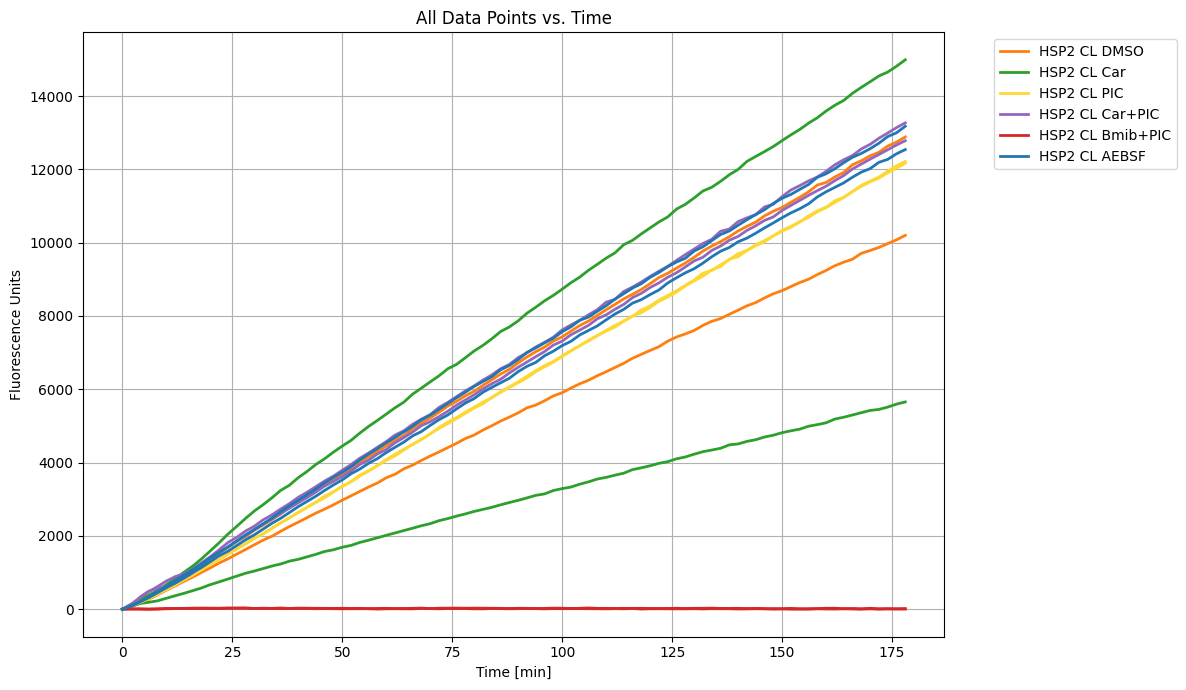

In [117]:
#@title Plot all data points (grouped dynamically by replicate family and treatment shades)
import re
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import matplotlib.colors as mcolors

# Create a temporary DataFrame with missing values filled for handling
df_plot = df_final.fillna('')

plt.figure(figsize=(12, 7))

# Extract x axis
x = pd.to_numeric(df_plot['Time [min]'], errors='coerce')

# Get all sample columns (excluding the Time column)
columns_to_plot = [col for col in df_plot.columns if col != 'Time [min]']

# Clean column names by removing replicate suffixes (_1, _2, etc.) to identify unique base groups
base_groups = list(dict.fromkeys([re.sub(r'(_*\d+|\.\d+)$', '', col) for col in columns_to_plot]))

# Robustly identify treatments and group prefixes
group_prefixes = set()
treatments_set = set()

for group in base_groups:
    parts = group.split()
    if len(parts) >= 2:
        treatments_set.add(parts[-1])
        group_prefixes.add(" ".join(parts[:-1]))
    else:
        treatments_set.add(group)
        group_prefixes.add('')

unique_prefixes = sorted(list(group_prefixes))
unique_treatments = sorted(list(treatments_set))

# Choose distinct base colors (hues) for each unique treatment
base_colors = ['#1f77b4', '#d62728', '#2ca02c', '#9467bd', '#ff7f0e', '#fdd835', '#e377c2', '#7f7f7f', '#bcbd22', '#17becf']
treatment_color_map = {treat: base_colors[i % len(base_colors)] for i, treat in enumerate(unique_treatments)}

def get_robust_color(base_name):
    treatment = unique_treatments[0] if unique_treatments else ''
    prefix = unique_prefixes[0] if unique_prefixes else ''

    # Match treatment (last word) and prefix (preceding words)
    parts = base_name.split()
    if len(parts) >= 2:
        treatment = parts[-1]
        prefix = " ".join(parts[:-1])
    else:
        treatment = base_name
        prefix = ''

    base_hex = treatment_color_map.get(treatment, '#7f7f7f')
    base_rgb = mcolors.to_rgb(base_hex)

    # Generate light/dark shades dynamically depending on the group prefix's index
    if len(unique_prefixes) > 1 and prefix in unique_prefixes:
        prefix_idx = unique_prefixes.index(prefix)
        factor = 0.6 + (prefix_idx / (len(unique_prefixes) - 1)) * 0.7
        shaded_rgb = np.clip(np.array(base_rgb) * factor, 0, 1)
        return mcolors.to_hex(shaded_rgb)
    return base_hex

# Track which groups have been added to the legend
legend_added = set()

for col in columns_to_plot:
    base_name = re.sub(r'(_*\d+|\.\d+)$', '', col)
    color = get_robust_color(base_name)

    y = pd.to_numeric(df_plot[col], errors='coerce')

    # All lines plotted as solid lines
    linestyle = '-'
    linewidth = 2.0

    # Only add the base label once to the legend
    if base_name not in legend_added:
        plt.plot(x, y, label=base_name, color=color, linewidth=linewidth, linestyle=linestyle)
        legend_added.add(base_name)
    else:
        plt.plot(x, y, color=color, linewidth=linewidth, linestyle=linestyle)

plt.xlabel('Time [min]')
plt.ylabel('Fluorescence Units')
plt.title('All Data Points vs. Time')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True)
plt.tight_layout()
plt.show()

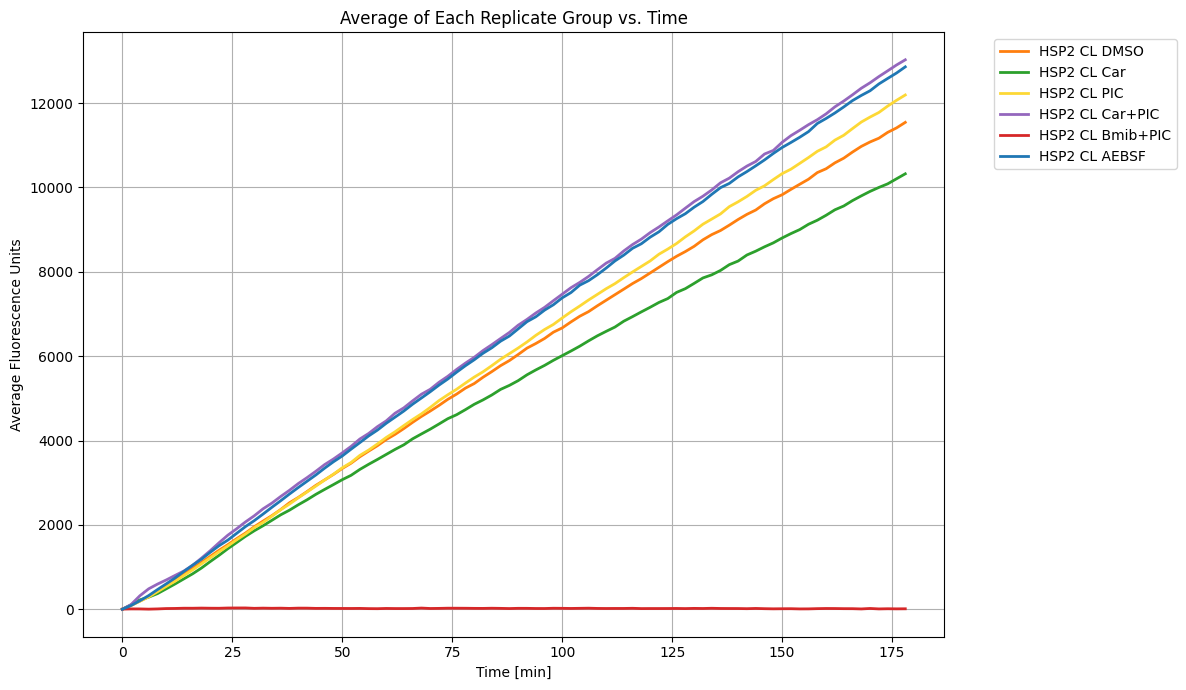

In [118]:
#@title Calculate and Graph Average per Replicate Group
import re
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import matplotlib.colors as mcolors

# 1. Identify unique replicate groups (base names) using df_final since df_normalized is inactive
replicate_cols = df_final.columns.drop('Time [min]', errors='ignore')

# Extract unique base replicate names preserving order
seen_base_reps = set()
base_replicates = []
for col in replicate_cols:
    base_name = re.sub(r'(_\d+)$', '', col)
    if base_name not in seen_base_reps:
        base_replicates.append(base_name)
        seen_base_reps.add(base_name)

# Calculate row-wise averages
combined_data = {'Time [min]': df_final['Time [min]']}
for base_rep in base_replicates:
    group_cols = [col for col in replicate_cols if col.startswith(base_rep + '_') or col == base_rep]
    combined_data[base_rep] = df_final[group_cols].mean(axis=1)

df_averages = pd.DataFrame(combined_data)

# 2. Graphing using the robust dynamic color matching logic
group_prefixes = set()
treatments_set = set()

for group in base_replicates:
    parts = group.split()
    if len(parts) >= 2:
        treatments_set.add(parts[-1])
        group_prefixes.add(" ".join(parts[:-1]))
    else:
        treatments_set.add(group)
        group_prefixes.add('')

unique_prefixes = sorted(list(group_prefixes))
unique_treatments = sorted(list(treatments_set))

# Choose distinct base colors (hues) for each unique treatment
base_colors = ['#1f77b4', '#d62728', '#2ca02c', '#9467bd', '#ff7f0e', '#fdd835', '#e377c2', '#7f7f7f', '#bcbd22', '#17becf']
treatment_color_map = {treat: base_colors[i % len(base_colors)] for i, treat in enumerate(unique_treatments)}

def get_robust_color(base_name):
    treatment = unique_treatments[0] if unique_treatments else ''
    prefix = unique_prefixes[0] if unique_prefixes else ''

    # Match treatment (last word) and prefix (preceding words)
    parts = base_name.split()
    if len(parts) >= 2:
        treatment = parts[-1]
        prefix = " ".join(parts[:-1])
    else:
        treatment = base_name
        prefix = ''

    base_hex = treatment_color_map.get(treatment, '#7f7f7f')
    base_rgb = mcolors.to_rgb(base_hex)

    # Generate light/dark shades dynamically depending on the group prefix's index
    if len(unique_prefixes) > 1 and prefix in unique_prefixes:
        prefix_idx = unique_prefixes.index(prefix)
        factor = 0.6 + (prefix_idx / (len(unique_prefixes) - 1)) * 0.7
        shaded_rgb = np.clip(np.array(base_rgb) * factor, 0, 1)
        return mcolors.to_hex(shaded_rgb)
    return base_hex

# Plotting
plt.figure(figsize=(12, 7))
x = df_averages['Time [min]']

for group in base_replicates:
    color = get_robust_color(group)
    y = df_averages[group]
    plt.plot(x, y, label=group, color=color, linewidth=2)

plt.xlabel('Time [min]')
plt.ylabel('Average Fluorescence Units')
plt.title('Average of Each Replicate Group vs. Time')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True)
plt.tight_layout()
plt.show()

Enter the R² standard deviation cutoff (e.g., 0.001): 0.001
Enter the start time for the range in minutes (e.g., 0): 0
Enter the end time for the range in minutes (e.g., 120): 120
Enter the minimum number of consecutive data points (e.g., 10): 10
Enter the maximum number of consecutive data points (e.g., 20): 20

Configuration updated successfully:
- R² Std Dev Cutoff: 0.001
- Time Range: 0 to 120 minutes
- Points Range: 10 to 20 points


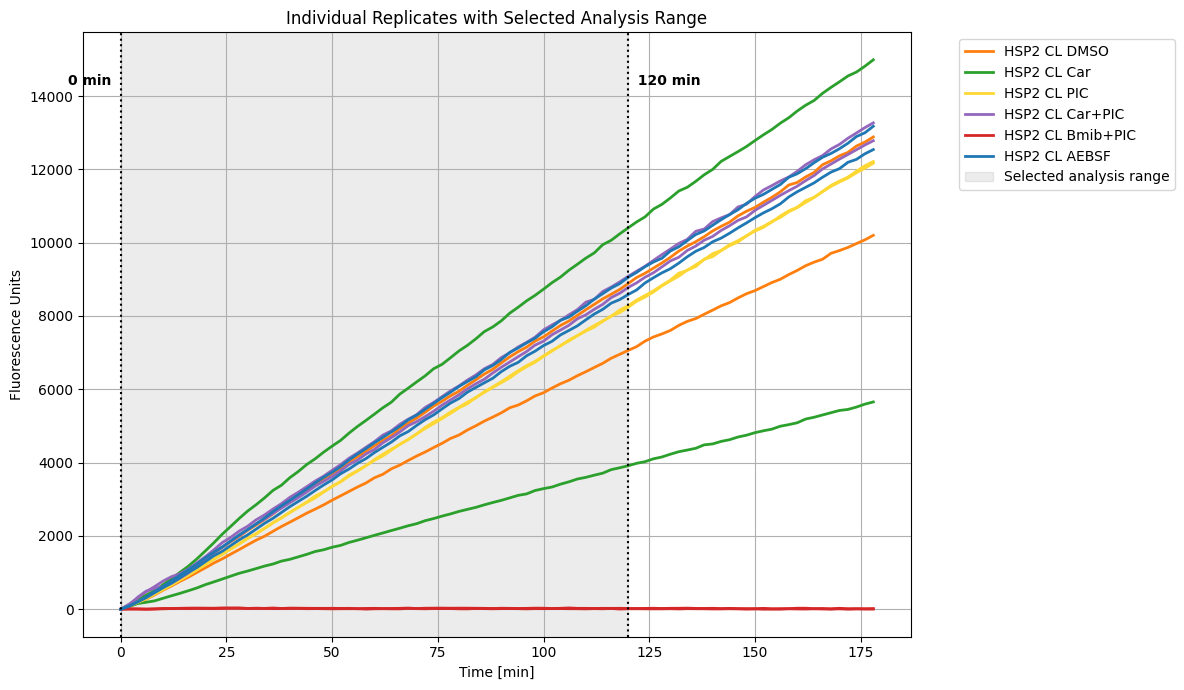

In [119]:
#@title Analysis Configuration Settings
import re
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import matplotlib.colors as mcolors

# 1. Gather configuration via input
std_dev_cutoff = float(input("Enter the R² standard deviation cutoff (e.g., 0.001): "))
start_time = int(input("Enter the start time for the range in minutes (e.g., 0): "))
end_time = int(input("Enter the end time for the range in minutes (e.g., 120): "))
min_points = int(input("Enter the minimum number of consecutive data points (e.g., 10): "))
max_points = int(input("Enter the maximum number of consecutive data points (e.g., 20): "))

print("\nConfiguration updated successfully:")
print(f"- R² Std Dev Cutoff: {std_dev_cutoff}")
print(f"- Time Range: {start_time} to {end_time} minutes")
print(f"- Points Range: {min_points} to {max_points} points")

# 2. Render plot highlighting the selected analysis range with robust color group mapping
df_plot = df_final.fillna('')
plt.figure(figsize=(12, 7))

# Extract x axis
x = pd.to_numeric(df_plot['Time [min]'], errors='coerce')
columns_to_plot = [col for col in df_plot.columns if col != 'Time [min]']
base_groups = list(dict.fromkeys([re.sub(r'(_\d+|\.\d+)$', '', col) for col in columns_to_plot]))

group_prefixes = set()
treatments_set = set()

for group in base_groups:
    parts = group.split()
    if len(parts) >= 2:
        treatments_set.add(parts[-1])
        group_prefixes.add(" ".join(parts[:-1]))
    else:
        treatments_set.add(group)
        group_prefixes.add('')

unique_prefixes = sorted(list(group_prefixes))
unique_treatments = sorted(list(treatments_set))

base_colors = ['#1f77b4', '#d62728', '#2ca02c', '#9467bd', '#ff7f0e', '#fdd835', '#e377c2', '#7f7f7f', '#bcbd22', '#17becf']
treatment_color_map = {treat: base_colors[i % len(base_colors)] for i, treat in enumerate(unique_treatments)}

def get_robust_color(base_name):
    treatment = unique_treatments[0] if unique_treatments else ''
    prefix = unique_prefixes[0] if unique_prefixes else ''

    # Match treatment (last word) and prefix (preceding words)
    parts = base_name.split()
    if len(parts) >= 2:
        treatment = parts[-1]
        prefix = " ".join(parts[:-1])
    else:
        treatment = base_name
        prefix = ''

    base_hex = treatment_color_map.get(treatment, '#7f7f7f')
    base_rgb = mcolors.to_rgb(base_hex)

    # Generate light/dark shades dynamically depending on the group prefix's index
    if len(unique_prefixes) > 1 and prefix in unique_prefixes:
        prefix_idx = unique_prefixes.index(prefix)
        factor = 0.6 + (prefix_idx / (len(unique_prefixes) - 1)) * 0.7
        shaded_rgb = np.clip(np.array(base_rgb) * factor, 0, 1)
        return mcolors.to_hex(shaded_rgb)
    return base_hex

legend_added = set()
for col in columns_to_plot:
    base_name = re.sub(r'(_\d+|\.\d+)$', '', col)
    color = get_robust_color(base_name)
    y = pd.to_numeric(df_plot[col], errors='coerce')

    # Plot everything as clean solid lines
    linestyle = '-'
    linewidth = 2.0

    if base_name not in legend_added:
        plt.plot(x, y, label=base_name, color=color, linewidth=linewidth, linestyle=linestyle)
        legend_added.add(base_name)
    else:
        plt.plot(x, y, color=color, linewidth=linewidth, linestyle=linestyle)

plt.axvspan(start_time, end_time, color='gray', alpha=0.15, label='Selected analysis range')
plt.axvline(x=start_time, color='black', linestyle=':', linewidth=1.5)
plt.axvline(x=end_time, color='black', linestyle=':', linewidth=1.5)

y_min, y_max = plt.ylim()
text_y_position = y_min + (y_max - y_min) * 0.92

plt.text(start_time, text_y_position, f'{start_time} min  ', rotation=0, verticalalignment='center', horizontalalignment='right', fontweight='bold')
plt.text(end_time, text_y_position, f'  {end_time} min', rotation=0, verticalalignment='center', horizontalalignment='left', fontweight='bold')

plt.xlabel('Time [min]')
plt.ylabel('Fluorescence Units')
plt.title('Individual Replicates with Selected Analysis Range')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True)
plt.tight_layout()
plt.show()

# These code cell below can take quite some time depends on how much data you have. Should be under 1 minute most of the time

In [120]:
#@title Calculate Candidate Slopes for Individual Replicates

import re
import pandas as pd
import numpy as np
from scipy import stats

# 1. Validate variables and constraints
if 'start_time' not in locals() or 'end_time' not in locals() or 'min_points' not in locals() or 'max_points' not in locals():
    raise ValueError("Please ensure start_time, end_time, min_points, and max_points are defined in your settings cell.")

if start_time >= end_time:
    raise ValueError(f"Invalid time range: start_time ({start_time}) must be less than end_time ({end_time}).")

if not (2 <= min_points <= max_points):
    raise ValueError(f"Invalid point constraints: Must satisfy 2 <= min_points ({min_points}) <= max_points ({max_points}).")

# 2. Filter data within the requested time range (inclusive)
df_range = df_final[(df_final['Time [min]'] >= start_time) & (df_final['Time [min]'] <= end_time)].copy()
df_range = df_range.sort_values(by='Time [min]').reset_index(drop=True)

time_series = df_range['Time [min]'].values
num_rows = len(df_range)
replicate_cols = [col for col in df_final.columns if col != 'Time [min]']

candidate_slopes = []

# 3. Iterate through each individual replicate column
for col in replicate_cols:
    # Identify sample group by stripping only the trailing replicate suffix (e.g. _1, _2)
    sample_group = re.sub(r'(_\d+)$', '', col)

    y_series = pd.to_numeric(df_range[col], errors='coerce').values

    # Iterate through all allowed window sizes (number of data points)
    for window_size in range(min_points, min(max_points + 1, num_rows + 1)):
        # Iterate through every possible consecutive index slice
        for start_idx in range(0, num_rows - window_size + 1):
            end_idx = start_idx + window_size

            x_window = time_series[start_idx:end_idx]
            y_window = y_series[start_idx:end_idx]

            # Exclude points containing missing or non-numeric values (prevent fitting across gaps)
            valid_mask = ~np.isnan(x_window) & ~np.isnan(y_window)
            x_clean = x_window[valid_mask]
            y_clean = y_window[valid_mask]

            # The cleaned slice must still have exactly the continuous window size (no internal gaps allowed)
            if len(x_clean) < window_size or len(x_clean) < 2:
                continue

            # Prevent fitting if there is no variance in independent variable
            if np.all(x_clean == x_clean[0]):
                continue

            # Calculate regression parameters
            slope, intercept, r_value, p_value, std_err = stats.linregress(x_clean, y_clean)
            r_squared = r_value ** 2

            candidate_slopes.append({
                'Sample Group': sample_group,
                'Replicate Name': col,
                'Window Start Time': x_clean[0],
                'Window End Time': x_clean[-1],
                'Number of Points': len(x_clean),
                'Slope': slope,
                'Intercept': intercept,
                'R-squared': r_squared
            })

# 4. Display candidate slopes
if candidate_slopes:
    df_candidates = pd.DataFrame(candidate_slopes)
    df_candidates_sorted = df_candidates.sort_values(by=['Sample Group', 'Replicate Name', 'R-squared'], ascending=[True, True, False]).reset_index(drop=True)

    print(f"Generated {len(df_candidates_sorted)} candidate slopes.")
    '''display(df_candidates_sorted.style.format({
        'Window Start Time': '{:.0f}',
        'Window End Time': '{:.0f}',
        'Slope': '{:.4f}',
        'Intercept': '{:.4f}',
        'R-squared': '{:.6f}'
    }))'''
else:
    print("No candidate slopes met the criteria. Check your configuration or data range.")

Generated 6204 candidate slopes.


In [ ]:
#@title **(INACTIVE)** Obtain all possible starting points + # of points per slice Slope and $R^2$

# Initialize a list to store regression results
regression_results = []

num_rows = len(df_summary_stats_multiindex)

# Iterate through possible numbers of points per slice, starting from 8 up to num_rows
for points_per_slice in range(minimum_time, num_rows + 1):
    # Iterate through every possible starting index for the current points_per_slice
    # An implicit stride of 1 covers "every starting point"
    for start_idx in range(0, num_rows - points_per_slice + 1):
        end_idx = start_idx + points_per_slice

        # Extract the slice of data
        slice_df = df_summary_stats_multiindex.iloc[start_idx:end_idx].copy()

        # Ensure 'Time [min]' is numeric
        x = slice_df['Time [min]'].astype(float)

        # Get the actual start and end time values for the slice
        slice_start_time = x.iloc[0]
        slice_end_time = x.iloc[-1]

        # Iterate through each base replicate group
        # `base_replicates` should be available from previous cells (e.g., E0EHzlMJpAf1)
        for base_rep in base_replicates:
            avg_col_name = (base_rep, 'Avg (x100)') # Use the scaled column name

            # Ensure 'Avg' column is numeric
            y = slice_df[avg_col_name].astype(float)

            # Perform linear regression only if there's enough data (at least 2 points)
            if len(x) >= 2 and len(y) >= 2:
                # slope, intercept, r_value, p_value, std_err
                slope, intercept, r_value, p_value, std_err = stats.linregress(x, y)
                r_squared = r_value**2

                regression_results.append({
                    'Replicate Group': base_rep,
                    'Time Slice (min)': f'{slice_start_time:.0f}-{slice_end_time:.0f}',
                    'Number of Points': points_per_slice,
                    'R-squared': r_squared,
                    'Slope': slope
                })

# Create a DataFrame from the results if any were generated
if regression_results:
    df_regression_summary = pd.DataFrame(regression_results)

    # Sort the DataFrame by 'Slope' in descending order
    df_regression_summary_sorted = df_regression_summary.sort_values(by='Slope', ascending=False).reset_index(drop=True)

    print("\n--- Linear Regression Analysis for All Possible Slices (Sorted by Slope) ---")

    # Get unique replicate groups to display separate tables
    unique_replicate_groups = df_regression_summary_sorted['Replicate Group'].unique()

    for group in unique_replicate_groups:
        group_df = df_regression_summary_sorted[df_regression_summary_sorted['Replicate Group'] == group]
        print(f"\n--- Results for Replicate Group: {group} ---")
        # Display the DataFrame with formatted R-squared and Slope values
        display(group_df.style.format({'R-squared': '{:.4f}', 'Slope': '{:.4f}'}))

else:
    print("No regression results to display. Please check your data and slice parameters.")

In [121]:
#@title Select Top Slopes for Individual Replicates with Traceable IDs and R² Filtering

# --- User Input ---
try:
    top_n = int(input("Enter the number of top slopes to display per replicate (e.g., 5, 10, 20): "))
except ValueError:
    print("Invalid input. Defaulting to top 5 slopes.")
    top_n = 5

try:
    r2_filter_input = input("Enter minimum R² threshold to filter (e.g., 0.95) or leave blank for no filter: ").strip()
    if r2_filter_input:
        r2_threshold = float(r2_filter_input)
        print(f"Filtering for slices with R² >= {r2_threshold:.4f}")
    else:
        r2_threshold = None
        print("No R² filter applied.")
except ValueError:
    print("Invalid threshold entered. Proceeding with no R² filter.")
    r2_threshold = None

# Ensure df_candidates_sorted is available
if 'df_candidates_sorted' not in locals() or df_candidates_sorted.empty:
    print("Error: df_candidates_sorted is not available or is empty. Please run the 'Calculate Candidate Slopes' cell above.")
else:
    # Get all unique individual replicates
    unique_replicates = df_candidates_sorted['Replicate Name'].unique()

    all_results_html = []
    top_slices_list = []

    # Process each replicate
    for rep in unique_replicates:
        # Filter candidate slopes for this replicate
        df_rep = df_candidates_sorted[df_candidates_sorted['Replicate Name'] == rep].copy()

        # Apply R-squared filter if specified
        if r2_threshold is not None:
            df_rep = df_rep[df_rep['R-squared'] >= r2_threshold]

        # Get the top N based on highest Slope (descending)
        df_rep_top = df_rep.sort_values(by='Slope', ascending=False).head(top_n).reset_index(drop=True)

        if not df_rep_top.empty:
            # Generate simple numeric IDs (1, 2, 3... top_n)
            df_rep_top.insert(0, 'ID', [i + 1 for i in range(len(df_rep_top))])

            # Keep track of results
            top_slices_list.append(df_rep_top)

            # Create a display copy to add visual tab space before R-squared column
            df_display = df_rep_top[[
                'ID', 'Window Start Time', 'Window End Time', 'Number of Points', 'Slope', 'R-squared'
            ]].copy()

            # Rename column key to include &nbsp; characters (simulating a tab)
            tab_prefix = '&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;'
            df_display = df_display.rename(columns={'R-squared': f'{tab_prefix}R-squared'})

            # Create HTML representation for side-by-side presentation
            group_html = []
            group_html.append(f'<div style="flex: 1; min-width: 440px; margin: 10px; border: 1px solid #ddd; padding: 10px; border-radius: 5px; box-shadow: 2px 2px 5px rgba(0,0,0,0.05);">')
            group_html.append(f'<h4 style="margin-top: 0; color: #1f77b4;">Top {top_n} Slices for Replicate: {rep}</h4>')

            # Style and render HTML table, adding substantial right padding to the ID column to create a wider gap before 'Window Start Time'
            styled_table = df_display.style.format({
                'Window Start Time': '{:.0f}',
                'Window End Time': '{:.0f}',
                'Slope': '{:.4f}',
                f'{tab_prefix}R-squared': lambda x: f'{tab_prefix}{x:.4f}'
            }).set_properties(subset=['ID'], **{
                'min-width': '12px',
                'padding-right': '10px',
                'text-align': 'left'
            }).hide(axis='index').to_html()

            group_html.append(styled_table)
            group_html.append(f'</div>')
            all_results_html.append(''.join(group_html))

    # Display the combined HTML results
    if all_results_html:
        combined_html = f'<div style="display: flex; flex-wrap: wrap; justify-content: flex-start;">{" ".join(all_results_html)}</div>'
        display(HTML(combined_html))

        # Concatenate all top slices into a single DataFrame for subsequent cells to access
        highest_slopes_per_group = pd.concat(top_slices_list, ignore_index=True)
    else:
        print("No candidate slopes met the filtering criteria.")

Enter the number of top slopes to display per replicate (e.g., 5, 10, 20): 5
Enter minimum R² threshold to filter (e.g., 0.95) or leave blank for no filter: 
No R² filter applied.


ID,Window Start Time,Window End Time,Number of Points,Slope,R-squared
1,24,42,10,75.5485,0.9999
2,30,48,10,75.4303,0.9998
3,24,44,11,75.3182,0.9999
4,24,46,12,75.3077,0.9999
5,24,48,13,75.2912,0.9999
ID,Window Start Time,Window End Time,Number of Points,Slope,R-squared
1,24,42,10,79.4848,0.9998
2,30,48,10,79.4121,0.9998
3,24,46,12,79.3374,0.9999
4,24,44,11,79.3136,0.9998


In [109]:
#@title Interactive Replicate Slope Override Selection
import pandas as pd
from IPython.display import display, HTML

# Ensure we have the calculated candidates and the selected slices
if 'df_candidates_sorted' not in locals() or df_candidates_sorted.empty:
    print("Error: df_candidates_sorted is not available. Please run the calculation cells above.")
elif 'highest_slopes_per_group' not in locals() or highest_slopes_per_group.empty:
    print("Error: No top slope slices are currently compiled in highest_slopes_per_group. Please run cell PkpSGz82lyaq first.")
else:
    # 1. Show user unique replicates currently available in the top slices
    unique_reps = sorted(highest_slopes_per_group['Replicate Name'].unique())
    print("=== Available Replicates for Override ===")
    for idx, rep in enumerate(unique_reps):
        print(f" {idx + 1}. {rep}")

    # 2. Let the user choose a replicate
    user_rep_choice = input("\nEnter the number or exact name of the replicate to override: ").strip()
    selected_rep = None

    if user_rep_choice.isdigit():
        idx_choice = int(user_rep_choice) - 1
        if 0 <= idx_choice < len(unique_reps):
            selected_rep = unique_reps[idx_choice]
    elif user_rep_choice in unique_reps:
        selected_rep = user_rep_choice

    if not selected_rep:
        print("❌ Invalid replicate selection.")
    else:
        # Extract slices belonging strictly to this replicate from the global registry
        df_rep_slices = highest_slopes_per_group[highest_slopes_per_group['Replicate Name'] == selected_rep].copy().reset_index(drop=True)

        print(f"\n--- Current Slices for Replicate: {selected_rep} ---")
        display(df_rep_slices[['ID', 'Window Start Time', 'Window End Time', 'Number of Points', 'Slope', 'R-squared']])

        # 3. Let user select which numeric ID to swap with ID 1
        user_id_choice = input("\nEnter the Row ID number to make the NEW Top 1 slope (e.g. 2, 3): ")

        try:
            target_id = int(user_id_choice)
            # Find indices for Row ID 1 and Target ID in the subset
            idx_top = df_rep_slices[df_rep_slices['ID'] == 1].index
            idx_target = df_rep_slices[df_rep_slices['ID'] == target_id].index

            if len(idx_top) == 0:
                print("❌ Current Top row (ID 1) not found.")
            elif len(idx_target) == 0:
                print(f"❌ Row ID {target_id} not found in current options.")
            else:
                t_idx = idx_target[0]
                top_idx = idx_top[0]

                # Create temporary copy of row data to perform the swap
                row_top = df_rep_slices.iloc[top_idx].copy()
                row_target = df_rep_slices.iloc[t_idx].copy()

                # Swap all fields except the 'ID' itself
                fields_to_swap = [col for col in df_rep_slices.columns if col != 'ID']
                df_rep_slices.loc[top_idx, fields_to_swap] = row_target[fields_to_swap].values
                df_rep_slices.loc[t_idx, fields_to_swap] = row_top[fields_to_swap].values

                # Update the global df_candidates_sorted so subsequent graph/summary steps reflect this change
                # We find the matching entries in df_candidates_sorted and update them
                rep_mask = df_candidates_sorted['Replicate Name'] == selected_rep
                df_candidates_sorted_rep = df_candidates_sorted[rep_mask].copy()

                # Sort so our new top choice occupies the exact index 0 slot when sorted by highest R-squared
                # We achieve this by giving our selected favorite a perfect dummy R-squared (1.0001) in df_candidates_sorted
                target_start = row_target['Window Start Time']
                target_end = row_target['Window End Time']

                # Find matching row index in master sorted database
                master_target_idx = df_candidates_sorted[
                    (df_candidates_sorted['Replicate Name'] == selected_rep) &
                    (df_candidates_sorted['Window Start Time'] == target_start) &
                    (df_candidates_sorted['Window End Time'] == target_end)
                ].index

                if not master_target_idx.empty:
                    # Assign a slightly higher R-squared to bubble it to the absolute top of df_candidates_sorted
                    orig_top_r2 = df_candidates_sorted_rep['R-squared'].max()
                    df_candidates_sorted.loc[master_target_idx[0], 'R-squared'] = orig_top_r2 + 0.0001

                    # Re-sort to apply bubble-up globally
                    df_candidates_sorted = df_candidates_sorted.sort_values(
                        by=['Sample Group', 'Replicate Name', 'R-squared'],
                        ascending=[True, True, False]
                    ).reset_index(drop=True)

                # Update highest_slopes_per_group with the updated slice table
                non_rep_slices = highest_slopes_per_group[highest_slopes_per_group['Replicate Name'] != selected_rep]
                highest_slopes_per_group = pd.concat([non_rep_slices, df_rep_slices], ignore_index=True)

                print(f"\n✅ Successfully swapped row {target_id} into the Top 1 position for {selected_rep}!")
                print("Updated replicate table structure:")
                display(df_rep_slices[['ID', 'Window Start Time', 'Window End Time', 'Number of Points', 'Slope', 'R-squared']])

        except ValueError:
            print("❌ Invalid Row ID format. Please enter a valid integer.")

=== Available Replicates for Override ===
 1. FS CL AEBSF_1
 2. FS CL AEBSF_2
 3. FS CL Car+PIC_1
 4. FS CL Car+PIC_2
 5. FS CL Car_1
 6. FS CL Car_2
 7. FS CL DMSO_1
 8. FS CL DMSO_2
 9. FS CL PIC_1
 10. FS CL PIC_2


KeyboardInterrupt: Interrupted by user

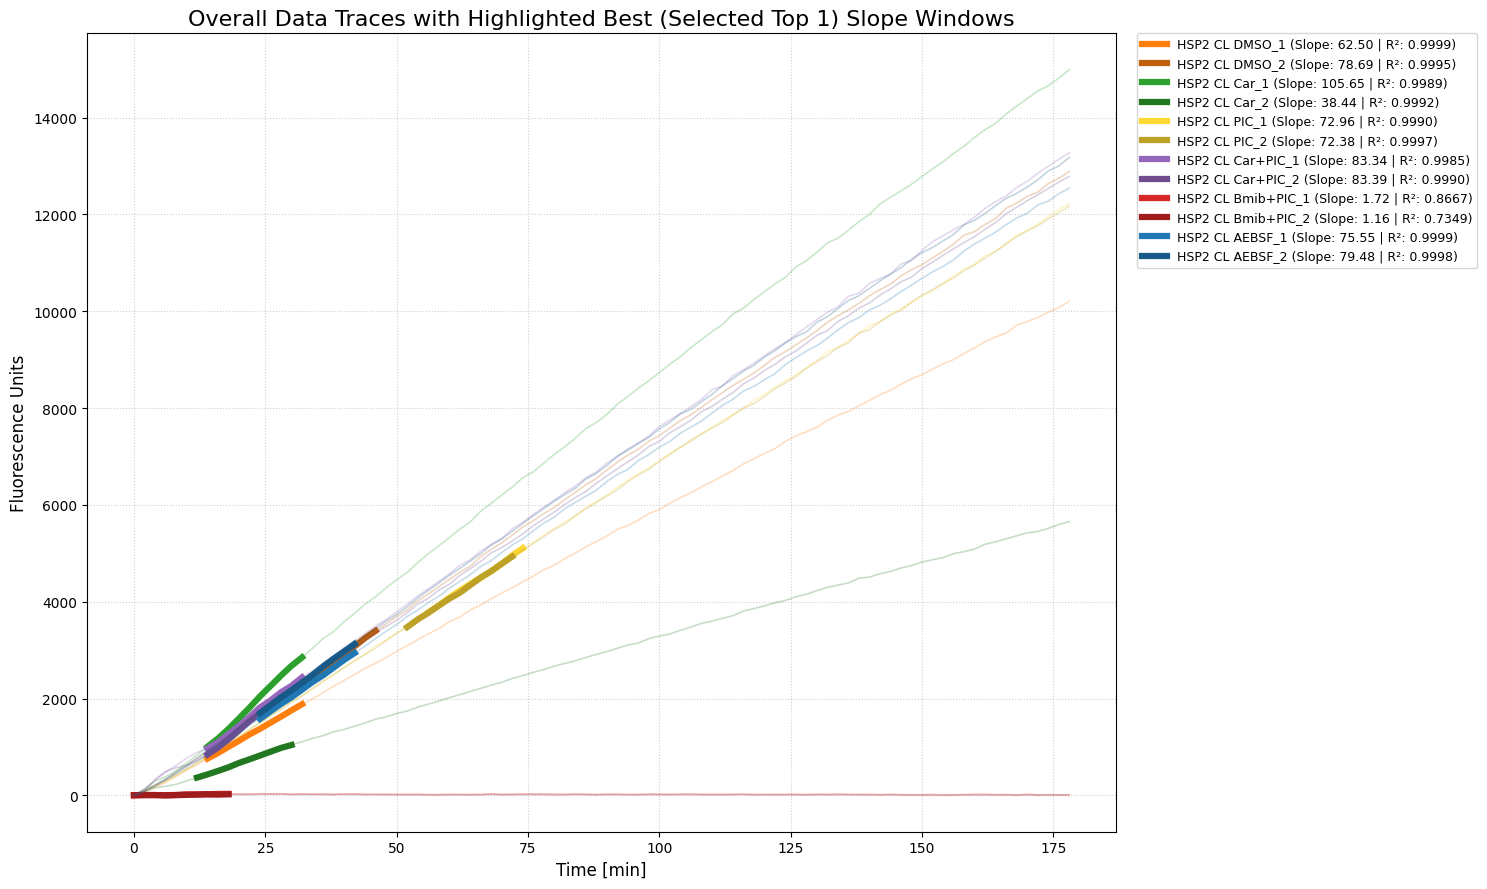

In [122]:
#@title Plot the Selected Top 1 Slope Window for All Replicates (Single Combined Graph)
import re
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import matplotlib.colors as mcolors

# Ensure required data structures are available
if 'df_final' not in locals() or df_final.empty:
    print("Error: df_final is not available. Please load the data first.")
else:
    # Determine where to extract the Top 1 slices from
    use_fallback = False
    if 'highest_slopes_per_group' in locals() and not highest_slopes_per_group.empty:
        # Extract the row with ID = 1 for each replicate (respecting filters/overrides)
        df_top_1 = highest_slopes_per_group[highest_slopes_per_group['ID'] == 1].copy()
    else:
        print("Note: 'highest_slopes_per_group' not found or empty. Falling back to the absolute highest slope from df_candidates_sorted.")
        use_fallback = True

    # Get unique replicates in the exact order they appear as columns in df_final
    all_cols = list(df_final.columns)
    replicate_cols = [col for col in all_cols if col != 'Time [min]']

    if use_fallback:
        if 'df_candidates_sorted' not in locals() or df_candidates_sorted.empty:
            print("Error: df_candidates_sorted is not available. Please run the calculation cells first.")
            df_top_1 = pd.DataFrame()
        else:
            top_1_slices = []
            unique_reps = [col for col in replicate_cols if col in df_candidates_sorted['Replicate Name'].values]
            for rep in unique_reps:
                df_rep = df_candidates_sorted[df_candidates_sorted['Replicate Name'] == rep]
                top_slice = df_rep.iloc[0].to_dict()
                top_1_slices.append(top_slice)
            df_top_1 = pd.DataFrame(top_1_slices)

    if not df_top_1.empty:
        # 2. Get unique group families to set consistent color schemes
        base_groups = list(dict.fromkeys([re.sub(r'(_\d+|\.\d+)$', '', col) for col in replicate_cols]))

        group_prefixes = set()
        treatments_set = set()

        for group in base_groups:
            parts = group.split()
            if len(parts) >= 2:
                treatments_set.add(parts[-1])
                group_prefixes.add(" ".join(parts[:-1]))
            else:
                treatments_set.add(group)
                group_prefixes.add('')

        unique_prefixes = sorted(list(group_prefixes))
        unique_treatments = sorted(list(treatments_set))

        # Distinct base colors (hues) for each unique treatment.
        base_colors = ['#1f77b4', '#d62728', '#2ca02c', '#9467bd', '#ff7f0e', '#fdd835', '#e377c2', '#7f7f7f', '#bcbd22', '#17becf']
        treatment_color_map = {treat: base_colors[i % len(base_colors)] for i, treat in enumerate(unique_treatments)}

        def get_robust_color(base_name):
            treatment = unique_treatments[0] if unique_treatments else ''
            prefix = unique_prefixes[0] if unique_prefixes else ''

            parts = base_name.split()
            if len(parts) >= 2:
                treatment = parts[-1]
                prefix = " ".join(parts[:-1])
            else:
                treatment = base_name
                prefix = ''

            base_hex = treatment_color_map.get(treatment, '#7f7f7f')
            base_rgb = mcolors.to_rgb(base_hex)

            # Generate light/dark shades dynamically depending on the group prefix's index
            if len(unique_prefixes) > 1 and prefix in unique_prefixes:
                prefix_idx = unique_prefixes.index(prefix)
                factor = 0.6 + (prefix_idx / (len(unique_prefixes) - 1)) * 0.7
                shaded_rgb = np.clip(np.array(base_rgb) * factor, 0, 1)
                return mcolors.to_hex(shaded_rgb)
            return base_hex

        # 3. Create a single large overall plot
        plt.figure(figsize=(15, 9))
        time_x = df_final['Time [min]'].values

        # Filter top 1 data to only include replicates that exist in df_final
        unique_reps = [col for col in replicate_cols if col in df_top_1['Replicate Name'].values]

        # Group replicates together by their base group to apply dynamic shading variance correctly
        reps_by_group = {}
        for rep in unique_reps:
            base_name = re.sub(r'(_\d+|\.\d+)$', '', rep)
            reps_by_group.setdefault(base_name, []).append(rep)

        # Plot in the exact order of base groups from df_final
        ordered_base_groups = list(dict.fromkeys([re.sub(r'(_\d+|\.\d+)$', '', rep) for rep in unique_reps]))

        for base_name in ordered_base_groups:
            reps = reps_by_group[base_name]
            base_hex = get_robust_color(base_name)
            base_rgb = mcolors.to_rgb(base_hex)

            for i, rep in enumerate(reps):
                # Generate unique shades for replicates in the same group
                if len(reps) > 1:
                    factor = 1.0 - (i * 0.25)
                    color = mcolors.to_hex(np.clip(np.array(base_rgb) * factor, 0, 1))
                else:
                    color = base_hex

                y_values = pd.to_numeric(df_final[rep], errors='coerce').values
                plt.plot(time_x, y_values, color=color, alpha=0.25, linewidth=1.2, linestyle='-')

                # Get chosen top 1 window coordinates for this replicate
                rep_slice = df_top_1[df_top_1['Replicate Name'] == rep]
                if not rep_slice.empty:
                    slice_info = rep_slice.iloc[0]
                    start_t = slice_info['Window Start Time']
                    end_t = slice_info['Window End Time']
                    slope = slice_info['Slope']
                    r2 = slice_info['R-squared']

                    # Filter window slice data
                    window_mask = (time_x >= start_t) & (time_x <= end_t)
                    x_window = time_x[window_mask]
                    y_window = y_values[window_mask]

                    # Overlay the thick best slope segment
                    label = f"{rep} (Slope: {slope:.2f} | R²: {r2:.4f})"
                    plt.plot(x_window, y_window, color=color, linewidth=4.5, linestyle='-', label=label)

        plt.xlabel('Time [min]', fontsize=12)
        plt.ylabel('Fluorescence Units', fontsize=12)
        plt.title('Overall Data Traces with Highlighted Best (Selected Top 1) Slope Windows', fontsize=16)
        plt.grid(True, linestyle=':', alpha=0.6)
        plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0., fontsize=9)
        plt.tight_layout()
        plt.show()

=== Available Sample Groups ===
 1. HSP2 CL DMSO
 2. HSP2 CL Car
 3. HSP2 CL PIC
 4. HSP2 CL Car+PIC
 5. HSP2 CL Bmib+PIC
 6. HSP2 CL AEBSF

Enter the number or the exact name of the sample group you want to plot: HSP2 CL PIC


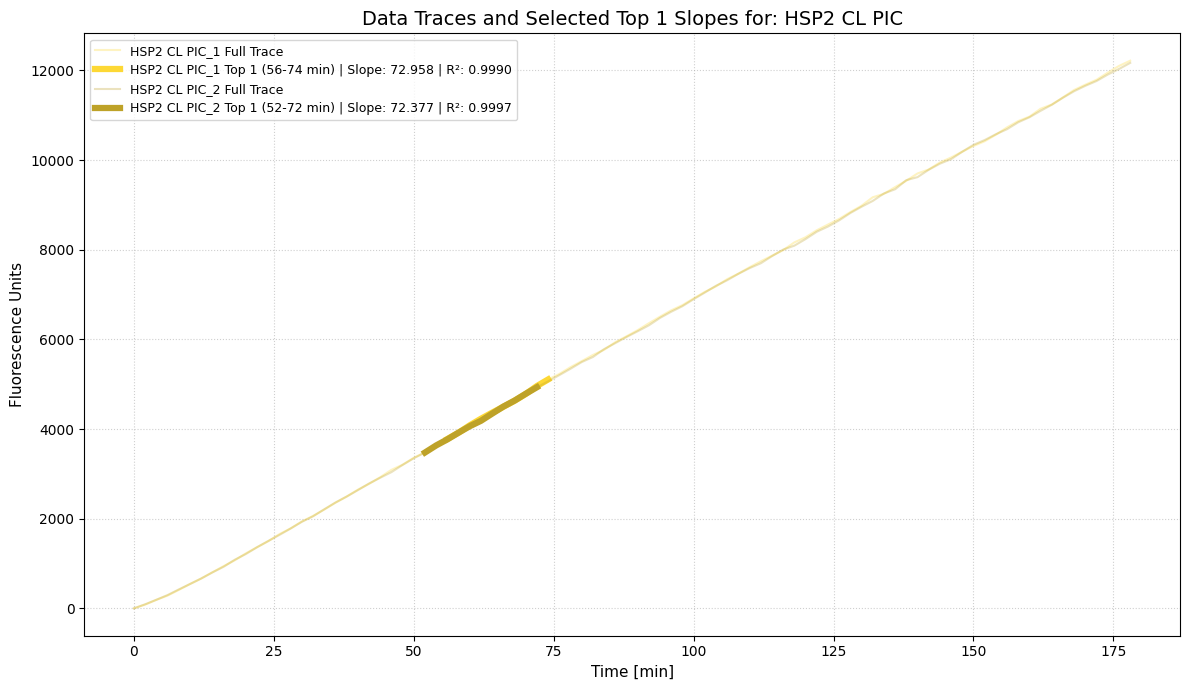

In [129]:
#@title Interactive Plot for a Single Selected Sample Group with Selected Top Slopes
import re
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import matplotlib.colors as mcolors

# Ensure required data structures are available
if 'df_final' not in locals() or df_final.empty:
    print("Error: df_final is not available. Please load the data first.")
else:
    # 1. Extract all columns except Time to identify replicates
    replicate_cols = [col for col in df_final.columns if col != 'Time [min]']

    # 2. Extract unique base sample groups
    base_groups = list(dict.fromkeys([re.sub(r'(_\d+|\.\d+)$', '', col) for col in replicate_cols]))

    # Robustly identify unique treatments and prefixes to determine consistent colors
    group_prefixes = set()
    treatments_set = set()

    for group in base_groups:
        parts = group.split()
        if len(parts) >= 2:
            treatments_set.add(parts[-1])
            group_prefixes.add(" ".join(parts[:-1]))
        else:
            treatments_set.add(group)
            group_prefixes.add('')

    unique_prefixes = sorted(list(group_prefixes))
    unique_treatments = sorted(list(treatments_set))

    # Choose distinct base colors (hues) for each unique treatment
    base_colors = ['#1f77b4', '#d62728', '#2ca02c', '#9467bd', '#ff7f0e', '#fdd835', '#e377c2', '#7f7f7f', '#bcbd22', '#17becf']
    treatment_color_map = {treat: base_colors[i % len(base_colors)] for i, treat in enumerate(unique_treatments)}

    def get_robust_color(base_name):
        treatment = unique_treatments[0] if unique_treatments else ''
        prefix = unique_prefixes[0] if unique_prefixes else ''

        # Match treatment (last word) and prefix (preceding words)
        parts = base_name.split()
        if len(parts) >= 2:
            treatment = parts[-1]
            prefix = " ".join(parts[:-1])
        else:
            treatment = base_name
            prefix = ''

        base_hex = treatment_color_map.get(treatment, '#7f7f7f')
        base_rgb = mcolors.to_rgb(base_hex)

        # Generate light/dark shades dynamically depending on the group prefix's index
        if len(unique_prefixes) > 1 and prefix in unique_prefixes:
            prefix_idx = unique_prefixes.index(prefix)
            factor = 0.6 + (prefix_idx / (len(unique_prefixes) - 1)) * 0.7
            shaded_rgb = np.clip(np.array(base_rgb) * factor, 0, 1)
            return mcolors.to_hex(shaded_rgb)
        return base_hex

    print("=== Available Sample Groups ===")
    for idx, group in enumerate(base_groups):
        print(f" {idx + 1}. {group}")
    print()

    # 3. Solicit user input
    user_input = input("Enter the number or the exact name of the sample group you want to plot: ").strip()

    # Resolve selection
    selected_group = None
    if user_input.isdigit():
        selected_idx = int(user_input) - 1
        if 0 <= selected_idx < len(base_groups):
            selected_group = base_groups[selected_idx]
    elif user_input in base_groups:
        selected_group = user_input

    if not selected_group:
        print(f"\n❌ Invalid selection. Please enter a number from 1 to {len(base_groups)} or match the name exactly.")
    else:
        # Find the column replicates belonging to this group
        group_replicates = [col for col in replicate_cols if re.sub(r'(_\d+|\.\d+)$', '', col) == selected_group]

        if not group_replicates:
            print(f"\nNo replicates found for sample group: '{selected_group}'")
        else:
            # Determine where to extract the Top 1 slices from
            use_fallback = False
            if 'highest_slopes_per_group' in locals() and not highest_slopes_per_group.empty:
                df_top_1 = highest_slopes_per_group[highest_slopes_per_group['ID'] == 1].copy()
            else:
                print("Note: 'highest_slopes_per_group' not found. Falling back to default top slopes in df_candidates_sorted.")
                use_fallback = True

            if use_fallback:
                if 'df_candidates_sorted' not in locals() or df_candidates_sorted.empty:
                    print("Error: df_candidates_sorted is not available. Please calculate candidate slopes first.")
                    df_top_1 = pd.DataFrame()
                else:
                    top_1_slices = []
                    for rep in group_replicates:
                        df_rep = df_candidates_sorted[df_candidates_sorted['Replicate Name'] == rep]
                        if not df_rep.empty:
                            top_1_slices.append(df_rep.iloc[0].to_dict())
                    df_top_1 = pd.DataFrame(top_1_slices)

            # 4. Generate the plot
            plt.figure(figsize=(12, 7))
            time_x = df_final['Time [min]'].values

            # Resolve overall color for the chosen group family
            base_hex = get_robust_color(selected_group)
            base_rgb = mcolors.to_rgb(base_hex)

            for i, col in enumerate(group_replicates):
                y_values = pd.to_numeric(df_final[col], errors='coerce').values

                # Generate unique shades for individual replicates
                if len(group_replicates) > 1:
                    factor = 1.0 - (i * 0.25)
                    shaded_rgb = np.clip(np.array(base_rgb) * factor, 0, 1)
                    color = mcolors.to_hex(shaded_rgb)
                else:
                    color = base_hex

                # Plot the complete overall data trace in lighter opacity
                plt.plot(time_x, y_values, color=color, alpha=0.3, linewidth=1.5, linestyle='-', label=f"{col} Full Trace")

                # Get chosen top 1 window coordinates for this replicate
                if not df_top_1.empty:
                    rep_slice = df_top_1[df_top_1['Replicate Name'] == col]
                    if not rep_slice.empty:
                        slice_info = rep_slice.iloc[0]
                        start_t = slice_info['Window Start Time']
                        end_t = slice_info['Window End Time']
                        slope = slice_info['Slope']
                        r2 = slice_info['R-squared']

                        # Filter window slice data
                        window_mask = (time_x >= start_t) & (time_x <= end_t)
                        x_window = time_x[window_mask]
                        y_window = y_values[window_mask]

                        # Overlay the thick best slope segment
                        label = f"{col} Top 1 ({start_t:.0f}-{end_t:.0f} min) | Slope: {slope:.3f} | R²: {r2:.4f}"
                        plt.plot(x_window, y_window, color=color, linewidth=4.5, linestyle='-', label=label)

            plt.xlabel('Time [min]', fontsize=11)
            plt.ylabel('Fluorescence Units', fontsize=11)
            plt.title(f'Data Traces and Selected Top 1 Slopes for: {selected_group}', fontsize=14)
            plt.grid(True, linestyle=':', alpha=0.6)
            plt.legend(fontsize=9, loc='best')
            plt.tight_layout()
            plt.show()


After this step (where you find slopes), then average them and note how close the slopes are. Probably we should have a table outputted.

In [124]:
#@title Average Top Slopes of Each Replicate and Find the Difference Between Them
import re
import pandas as pd
from IPython.display import display, HTML

# Ensure candidate slopes are available
if 'df_candidates_sorted' not in locals() or df_candidates_sorted.empty:
    print("Error: df_candidates_sorted is not available. Please run previous cells first.")
else:
    # Determine where to extract the Top 1 slices from
    use_fallback = False
    if 'highest_slopes_per_group' in locals() and not highest_slopes_per_group.empty:
        # Extract the row with ID = 1 for each replicate (respecting filters/overrides)
        df_top_1 = highest_slopes_per_group[highest_slopes_per_group['ID'] == 1].copy()
    else:
        use_fallback = True

    # Get unique replicates in the exact order they appear as columns in df_final
    replicate_cols = [col for col in df_final.columns if col != 'Time [min]']

    if use_fallback:
        top_1_slices = []
        unique_reps = [col for col in replicate_cols if col in df_candidates_sorted['Replicate Name'].values]
        for rep in unique_reps:
            df_rep = df_candidates_sorted[df_candidates_sorted['Replicate Name'] == rep]
            if not df_rep.empty:
                top_slice = df_rep.iloc[0].to_dict()
                top_1_slices.append(top_slice)
        df_top_1 = pd.DataFrame(top_1_slices)

    # 2. Group by the Sample Group to aggregate replicate values
    grouped = df_top_1.groupby('Sample Group')
    summary_rows = []

    for group_name, group_df in grouped:
        # Get slopes list
        slopes = group_df['Slope'].tolist()
        replicate_names = group_df['Replicate Name'].tolist()

        # Compute basic statistics
        avg_slope = group_df['Slope'].mean()

        # Calculate difference: if we have 2 replicates, do |rep1 - rep2|
        # If more or fewer, provide range (max - min)
        if len(slopes) == 2:
            diff_val = abs(slopes[0] - slopes[1])
            desc_detail = f"|{replicate_names[0]} - {replicate_names[1]}|"
        elif len(slopes) > 2:
            diff_val = max(slopes) - min(slopes)
            desc_detail = "Range (Max - Min)"
        else:
            diff_val = 0.0
            desc_detail = "Single Replicate"

        # Store details with highlighted numbers using HTML markup
        rep_slopes_str = ", ".join([
            f"{name}: <b style='font-size: 1.05em;'>{slope:.3f}</b>"
            for name, slope in zip(replicate_names, slopes)
        ])

        summary_rows.append({
            'Sample Group': group_name,
            'Replicates and Slopes': rep_slopes_str,
            'Average Slope': avg_slope,
            'Difference': diff_val,
            'Difference Method': desc_detail
        })

    df_summary = pd.DataFrame(summary_rows)

    print("\n=== Replicate Slopes Comparison Table ===\n")
    # Round numeric columns for cleaner presentation
    df_summary['Average Slope'] = df_summary['Average Slope'].round(4)
    df_summary['Difference'] = df_summary['Difference'].round(4)

    # Convert DataFrame to HTML and render to preserve markdown highlights
    html_table = df_summary.to_html(escape=False, index=False)
    display(HTML(html_table))


=== Replicate Slopes Comparison Table ===



Sample Group,Replicates and Slopes,Average Slope,Difference,Difference Method
HSP2 CL AEBSF,"HSP2 CL AEBSF_1: 75.548, HSP2 CL AEBSF_2: 79.485",77.5167,3.9364,|HSP2 CL AEBSF_1 - HSP2 CL AEBSF_2|
HSP2 CL Bmib+PIC,"HSP2 CL Bmib+PIC_1: 1.721, HSP2 CL Bmib+PIC_2: 1.161",1.4409,0.5606,|HSP2 CL Bmib+PIC_1 - HSP2 CL Bmib+PIC_2|
HSP2 CL Car,"HSP2 CL Car_1: 105.645, HSP2 CL Car_2: 38.436",72.0409,67.2091,|HSP2 CL Car_1 - HSP2 CL Car_2|
HSP2 CL Car+PIC,"HSP2 CL Car+PIC_1: 83.342, HSP2 CL Car+PIC_2: 83.388",83.3652,0.0455,|HSP2 CL Car+PIC_1 - HSP2 CL Car+PIC_2|
HSP2 CL DMSO,"HSP2 CL DMSO_1: 62.503, HSP2 CL DMSO_2: 78.688",70.5955,16.1848,|HSP2 CL DMSO_1 - HSP2 CL DMSO_2|
HSP2 CL PIC,"HSP2 CL PIC_1: 72.958, HSP2 CL PIC_2: 72.377",72.6674,0.5803,|HSP2 CL PIC_1 - HSP2 CL PIC_2|


In [ ]:
#@title Extract filtered samples into separate DataFrames (Low Std Dev R-squared) and Show data from higher to lower slopes



# --- User-configurable parameter (same as in PkpSGz82lyaq) ---
std_dev_cutoff = 0.001 # Set the desired R-squared standard deviation cutoff here
# ----------------------------------

if 'df_regression_summary_sorted' in locals() and not df_regression_summary_sorted.empty:
    print(f"\n--- Extracting individual filtered sample DataFrames (Std Dev R-squared < {std_dev_cutoff}) ---")

    # Initialize an empty dictionary to store the individual filtered DataFrames
    filtered_individual_sample_dataframes = {}

    # Get unique replicate groups from the sorted DataFrame
    unique_replicate_groups = df_regression_summary_sorted['Replicate Group'].unique()

    for group in unique_replicate_groups:
        # Filter data for the current replicate group and sort by R-squared (descending)
        # This is crucial for the standard deviation cutoff logic
        df_group_raw = df_regression_summary_sorted[
            df_regression_summary_sorted['Replicate Group'] == group
        ].sort_values(by='R-squared', ascending=False).reset_index(drop=True)

        selected_rows_data = []
        current_r_squared_values_for_std = []

        # Iterate through the R-squared sorted DataFrame for the current group
        for index, row in df_group_raw.iterrows():
            r_squared_val = row['R-squared']

            # Tentatively add the current R-squared value
            current_r_squared_values_for_std.append(r_squared_val)

            # Calculate standard deviation. Handle the case of a single element (std dev is NaN)
            if len(current_r_squared_values_for_std) == 1:
                current_std_dev = 0.0
            else:
                current_std_dev = pd.Series(current_r_squared_values_for_std).std()

            # Check if the standard deviation condition is met
            if current_std_dev < std_dev_cutoff:
                selected_rows_data.append(row.to_dict())
            else:
                # If adding this R-squared value makes the std dev >= cutoff,
                # then this row should not be included, and we stop.
                current_r_squared_values_for_std.pop() # Remove the last added R-squared
                break

        if selected_rows_data:
            df_filtered_group = pd.DataFrame(selected_rows_data)
            # Drop the 'Replicate Group' column as it's now redundant within the individual DataFrame
            df_filtered_group = df_filtered_group.drop(columns=['Replicate Group']).reset_index(drop=True)

            # Store the filtered DataFrame in the dictionary
            filtered_individual_sample_dataframes[group] = df_filtered_group

            print(f"\nFiltered DataFrame for '{group}':")
            # display(df_filtered_group.style.format({'R-squared': '{:.4f}', 'Slope': '{:.4f}'}))

        else:
            print(f"\nNo filtered data found for '{group}' with R-squared standard deviation < {std_dev_cutoff}.")

    print("\nAll individual filtered sample DataFrames have been created and are accessible via the 'filtered_individual_sample_dataframes' dictionary.")
    print(f"Keys in 'filtered_individual_sample_dataframes': {list(filtered_individual_sample_dataframes.keys())}")

else:
    print("df_regression_summary_sorted is not available or is empty. Please run the previous cell that generates it.")

# import pandas as pd
# from IPython.display import HTML, display # Import HTML for rich display

if 'filtered_individual_sample_dataframes' in locals() and filtered_individual_sample_dataframes:
    print("\n--- Sorting each filtered sample DataFrame by Slope (descending) and displaying side-by-side ---")

    all_tables_html = [] # List to collect HTML representations of tables

    for group_name, df_sample in filtered_individual_sample_dataframes.items():
        if not df_sample.empty:
            # Sort the DataFrame by 'Slope' in descending order
            df_sorted_by_slope = df_sample.sort_values(by='Slope', ascending=False).reset_index(drop=True)

            # Convert each styled DataFrame to HTML
            table_html = df_sorted_by_slope.style.format({'R-squared': '{:.4f}', 'Slope': '{:.4f}'}).to_html(index=False)

            # Add a title above each table and wrap it in a div for layout
            all_tables_html.append(f'<div style="flex: 1; min-width: 300px; margin: 10px; border: 1px solid #ddd; padding: 10px;">')
            all_tables_html.append(f'<h4>Sorted Results for Replicate Group: {group_name}</h4>')
            all_tables_html.append(table_html)
            all_tables_html.append(f'</div>')
        else:
            # Add a placeholder for empty DataFrames to maintain layout if needed, or just print
            all_tables_html.append(f'<div style="flex: 1; min-width: 300px; margin: 10px; border: 1px solid #ddd; padding: 10px;">')
            all_tables_html.append(f'<h4>Sorted Results for Replicate Group: {group_name}</h4>')
            all_tables_html.append(f'<p>DataFrame is empty and cannot be sorted.</p>')
            all_tables_html.append(f'</div>')

    # Combine all individual table HTMLs into a single flex container
    if all_tables_html:
        combined_html = f'<div style="display: flex; flex-wrap: wrap; justify-content: flex-start;">{" ".join(all_tables_html)}</div>'
        display(HTML(combined_html))
    else:
        print("No filtered individual sample DataFrames were found to sort and display.")

else:
    print("filtered_individual_sample_dataframes is not available or is empty. Please run the previous cell that generates it.")


In [ ]:
#@title Highest slope for each sample in the filtered tables


# Ensure filtered_individual_sample_dataframes and df_summary_stats_multiindex are available
if 'filtered_individual_sample_dataframes' not in locals() or not filtered_individual_sample_dataframes:
    print("Error: filtered_individual_sample_dataframes is not available or is empty. Please run the preceding cells that generate it.")
elif 'df_summary_stats_multiindex' not in locals() or df_summary_stats_multiindex.empty:
    print("Error: df_summary_stats_multiindex is not available or is empty. Please run the previous data processing cells.")
else:
    print("--- Highest Slope for Each Replicate Group from Filtered DataFrames ---")

    highest_slopes_from_filtered = []

    for group_name, df_group in filtered_individual_sample_dataframes.items():
        if not df_group.empty:
            # Find the row with the maximum slope in the current filtered DataFrame
            # Explicitly sort by 'Slope' to guarantee finding the highest slope.
            highest_slope_row_for_group = df_group.sort_values(by='Slope', ascending=False).iloc[0].to_dict()
            highest_slope_row_for_group['Replicate Group'] = group_name # Add group name back for clarity
            highest_slopes_from_filtered.append(highest_slope_row_for_group)

    if highest_slopes_from_filtered:
        df_highest_slopes = pd.DataFrame(highest_slopes_from_filtered)
        # Reorder columns to have 'Replicate Group' first for better display
        cols = ['Replicate Group'] + [col for col in df_highest_slopes.columns if col != 'Replicate Group']
        df_highest_slopes = df_highest_slopes[cols]

        # Display the results with formatting
        display(df_highest_slopes.style.format({'R-squared': '{:.4f}', 'Slope': '{:.4f}'}))

        # Store the result in a variable for potential further use
        highest_slopes_per_group = df_highest_slopes

        # --- Plotting each highest slope in small subplots ---
        if not df_highest_slopes.empty:
            num_plots = len(df_highest_slopes)
            # Calculate grid dimensions for subplots (roughly square)
            num_cols = int(math.ceil(math.sqrt(num_plots)))
            num_rows = int(math.ceil(num_plots / num_cols))

            fig, axes = plt.subplots(num_rows, num_cols, figsize=(num_cols * 5, num_rows * 4), squeeze=False)
            axes = axes.flatten() # Flatten the 2D array of axes for easy iteration

            # Ensure 'Time [min]' in df_summary_stats_multiindex is numeric for comparison
            df_summary_stats_multiindex['Time [min]'] = pd.to_numeric(df_summary_stats_multiindex['Time [min]'], errors='coerce')

            for i, (index, row) in enumerate(df_highest_slopes.iterrows()):
                ax = axes[i]
                replicate_group = row['Replicate Group']
                slice_time_label = row['Time Slice (min)']

                # Extract start and end time from slice_time_label
                time_match = re.search(r'(\d+)-(\d+)', slice_time_label)
                if time_match:
                    start_time = int(time_match.group(1))
                    end_time = int(time_match.group(2))
                else:
                    print(f"Warning: Could not parse time slice label: {slice_time_label}. Using full range for {replicate_group}.")
                    start_time = df_summary_stats_multiindex['Time [min]'].min()
                    end_time = df_summary_stats_multiindex['Time [min]'].max()

                # Filter df_summary_stats_multiindex to get the data for the selected slice
                slice_data_for_plot = df_summary_stats_multiindex[
                    (df_summary_stats_multiindex['Time [min]'] >= start_time) &
                    (df_summary_stats_multiindex['Time [min]'] <= end_time)
                ].copy()

                x_data = slice_data_for_plot['Time [min]'].astype(float)
                y_data = slice_data_for_plot[(replicate_group, 'Avg (x100)')].astype(float)

                if len(x_data) < 2 or len(y_data) < 2:
                    ax.set_title(f'{replicate_group} ({slice_time_label})\nNo data to plot')
                    ax.set_visible(False) # Hide empty subplot
                else:
                    # Recalculate regression for the exact slice data for plotting accuracy
                    slope, intercept, r_value, p_value, std_err = stats.linregress(x_data, y_data)
                    r_squared = r_value**2

                    # Generate the best-fit line
                    x_fit = np.array([x_data.min(), x_data.max()])
                    y_fit = slope * x_fit + intercept

                    # Plot original data points
                    ax.scatter(x_data, y_data, color='blue', s=20, label='Data')
                    # Plot best-fit line
                    ax.plot(x_fit, y_fit, color='red', linestyle='--', label='Fit')

                    ax.set_title(f'{replicate_group} ({slice_time_label})\nSlope={slope:.2f}, R2={r_squared:.2f}', fontsize=9)
                    ax.set_xlabel('Time [min]', fontsize=8)
                    ax.set_ylabel('Avg (x100)', fontsize=8)
                    ax.grid(True)
                    ax.tick_params(axis='both', which='major', labelsize=7)

            # Hide any unused subplots
            for j in range(i + 1, len(axes)):
                axes[j].set_visible(False)

            plt.tight_layout(rect=[0, 0, 1, 0.96]) # Adjust layout to prevent title overlap
            fig.suptitle('Highest Slope Slices for Each Replicate Group (Filtered)', fontsize=16)
            plt.show()
        else:
            print("No highest slope results from filtered data to plot.")
    else:
        print("No highest slopes found from the filtered individual sample DataFrames to plot.")


Error: filtered_individual_sample_dataframes is not available or is empty. Please run the preceding cells that generate it.


In [ ]:
#@title IGNORE THIS
# #@title Choose Slice(s) to display

# import matplotlib.pyplot as plt
# from scipy import stats
# import pandas as pd
# import numpy as np # Make sure numpy is imported for np.array
# import re # Make sure re is imported for re.search

# # Ensure df_regression_summary_sorted and df_summary_stats_multiindex are available
# # In previous cells, df_result_set was assigned df_regression_summary_sorted.copy()
# # We use df_regression_summary_sorted directly here as it holds all results before std_dev filtering
# if 'df_regression_summary_sorted' not in locals() or df_regression_summary_sorted.empty:
#     print("Error: df_regression_summary_sorted is not available or is empty. Please run the previous cell (PkpSGz82lyaq) that generates it.")
# elif 'df_summary_stats_multiindex' not in locals() or df_summary_stats_multiindex.empty:
#     print("Error: df_summary_stats_multiindex is not available or is empty. Please run the previous data processing cells.")
# else:
#     # Get std_dev_cutoff from the previous cell, or use a default if not found
#     # This parameter is defined in cell PkpSGz82lyaq
#     std_dev_cutoff = locals().get('std_dev_cutoff', 0.001)
#     print(f"Using R-squared standard deviation cutoff: {std_dev_cutoff}")

#     # Get unique replicate groups from the full sorted regression summary
#     available_replicate_groups = df_regression_summary_sorted['Replicate Group'].unique().tolist()
#     print("Available Replicate Groups:", available_replicate_groups)

#     # Step 1: User chooses a Replicate Group
#     selected_group = None
#     while selected_group not in available_replicate_groups:
#         selected_group = input("Enter the Replicate Group you want to visualize: ")
#         if selected_group not in available_replicate_groups:
#             print(f"Invalid Replicate Group. Please choose from: {', '.join(available_replicate_groups)}")

#     # Filter df_regression_summary_sorted for the selected group
#     df_group_raw = df_regression_summary_sorted[
#         df_regression_summary_sorted['Replicate Group'] == selected_group
#     ].sort_values(by='R-squared', ascending=False).reset_index(drop=True)

#     # --- Apply the std_dev_cutoff filtering logic for the selected group, mirroring PkpSGz82lyaq ---
#     selected_rows_data_for_plot = []
#     current_r_squared_values_for_std = []

#     for index, row in df_group_raw.iterrows():
#         r_squared_val = row['R-squared']

#         current_r_squared_values_for_std.append(r_squared_val)

#         # Calculate standard deviation. Handle the case of a single element (std dev is NaN)
#         if len(current_r_squared_values_for_std) == 1:
#             current_std_dev = 0.0
#         else:
#             current_std_dev = pd.Series(current_r_squared_values_for_std).std()

#         # Check if the standard deviation condition is met
#         if current_std_dev < std_dev_cutoff:
#             selected_rows_data_for_plot.append(row.to_dict())
#         else:
#             # If adding this R-squared value makes the std dev >= cutoff, then this row should not be included, and we stop.
#             current_r_squared_values_for_std.pop() # Remove the last added R-squared
#             break

#     # This df_filtered_by_group now contains the slices that passed the std_dev_cutoff for the selected group
#     df_filtered_by_group = pd.DataFrame(selected_rows_data_for_plot)

#     if df_filtered_by_group.empty:
#         print(f"No results found for the selected Replicate Group: {selected_group} with R-squared standard deviation less than {std_dev_cutoff}.")
#     else:
#         print(f"\n--- Available slices for {selected_group} (filtered by Std Dev R-squared < {std_dev_cutoff}) ---")
#         # The user requested to remove the display of the table
#         # display(df_filtered_by_group.style.format({'R-squared': '{:.4f}', 'Slope': '{:.4f}'}))

#         # Step 2: User chooses row numbers from the filtered table
#         while True:
#             try:
#                 row_num_input_str = input(f"\nEnter row numbers (indices) from the above summary table for {selected_group}, comma-separated (e.g., '0,1') (0 to {len(df_filtered_by_group) - 1}): ")
#                 row_indices_str = [x.strip() for x in row_num_input_str.split(',')]
#                 row_indices = [int(x) for x in row_indices_str if x] # Convert to int, handle empty strings after split

#                 valid_indices = True
#                 if not row_indices:
#                     print("No row numbers entered. Please try again.")
#                     valid_indices = False
#                 else:
#                     for idx in row_indices:
#                         if not (0 <= idx < len(df_filtered_by_group)):
#                             print(f"Invalid row number: {idx}. Please enter indices within the displayed range for {selected_group}.")
#                             valid_indices = False
#                             break
#                 if valid_indices:
#                     break
#             except ValueError:
#                 print("Invalid input. Please enter comma-separated integers.")

#         plt.figure(figsize=(12, 7))
#         plt.title(f'Multiple Regression Slices and Fits for {selected_group}')
#         plt.xlabel('Time [min]')
#         plt.ylabel('Average of Sample (x100)') # Keep y-axis label consistent
#         plt.grid(True)

#         # Use a colormap to get distinct colors for multiple plots
#         colors = plt.cm.get_cmap('tab10', len(row_indices))

#         for i, row_index in enumerate(row_indices):
#             current_color = colors(i) # Get a unique color for each slice

#             # Get the selected regression result row from the filtered DataFrame
#             selected_row = df_filtered_by_group.iloc[row_index]

#             slice_time_label = selected_row['Time Slice (min)']
#             # The replicate_group is already known (selected_group)
#             r_squared_from_summary = selected_row['R-squared']
#             slope_from_summary = selected_row['Slope']

#             print(f"\nPreparing plot for: Row ID {row_index}, Time Slice: {slice_time_label}")

#             # Extract start and end time from slice_time_label
#             try:
#                 start_time_str, end_time_str = slice_time_label.split('-')
#                 start_time = int(start_time_str)
#                 end_time = int(end_time_str)
#             except ValueError:
#                 print(f"Error parsing time slice label: {slice_time_label}. Attempting to use full range.")
#                 start_time = df_summary_stats_multiindex['Time [min]'].min()
#                 end_time = df_summary_stats_multiindex['Time [min]'].max()

#             # Filter df_summary_stats_multiindex to get the data for the selected slice
#             # Ensure 'Time [min]' in df_summary_stats_multiindex is numeric for comparison
#             df_summary_stats_multiindex['Time [min]'] = pd.to_numeric(df_summary_stats_multiindex['Time [min]'], errors='coerce')

#             slice_data_for_plot = df_summary_stats_multiindex[
#                 (df_summary_stats_multiindex['Time [min]'] >= start_time) &
#                 (df_summary_stats_multiindex['Time [min]'] <= end_time)
#             ].copy()

#             x_data = slice_data_for_plot['Time [min]'].astype(float)
#             y_data = slice_data_for_plot[(selected_group, 'Avg (x100)')].astype(float) # Use the selected_group for column name

#             if len(x_data) < 2 or len(y_data) < 2:
#                 print(f"Error: Not enough data points to plot or perform regression for the selected slice (Row ID: {row_index}).")
#             else:
#                 # Recalculate regression for the exact slice data (to ensure fit line is accurate)
#                 slope, intercept, r_value, p_value, std_err = stats.linregress(x_data, y_data)
#                 r_squared = r_value**2

#                 # Generate the best-fit line
#                 x_fit = np.array([x_data.min(), x_data.max()])
#                 y_fit = slope * x_fit + intercept

#                 # Plot original data points
#                 plt.scatter(x_data, y_data, label=f'Row {row_index}: Data ({slice_time_label})', color=current_color, s=50, zorder=5)

#                 # Plot best-fit line
#                 plt.plot(x_fit, y_fit, color=current_color, linestyle='--', label=f'Row {row_index}: Fit (Slope={slope:.2f}, R2={r_squared:.2f})')

#         plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left') # Place legend outside the plot
#         plt.tight_layout() # Adjust layout to prevent legend overlap
#         plt.show()

In [ ]:
#@title Shows where each plot is on the overall graph

# Ensure df_summary_stats_multiindex and highest_slopes_per_group are available
if 'df_summary_stats_multiindex' not in locals() or df_summary_stats_multiindex.empty:
    print("Error: df_summary_stats_multiindex is not available or is empty. Please run the data processing cells.")
elif 'highest_slopes_per_group' not in locals() or highest_slopes_per_group.empty:
    print("Error: highest_slopes_per_group is not available or is empty. Please run the preceding cells that generate it.")
else:
    plt.figure(figsize=(15, 9))
    plt.title('Overall Data with Highlighted Highest Slope Slices', fontsize=16)
    plt.xlabel('Time [min]', fontsize=12)
    plt.ylabel('Average of Sample (x100)', fontsize=12)
    plt.grid(True, linestyle='--', alpha=0.7)

    # Get a list of unique replicate group names from the MultiIndex for consistent coloring
    replicate_groups_for_coloring = [col[0] for col in df_summary_stats_multiindex.columns if col[1] == 'Avg (x100)']
    num_unique_replicate_groups = len(replicate_groups_for_coloring)

    # Retrieve the 'tab10' colormap object directly
    cmap_object = plt.colormaps['tab10']

    # Create a dictionary to map each replicate group name to a specific color
    # This ensures consistency between overall plot and highlight plot, cycling colors if needed
    group_color_dict = {group_name: cmap_object(i % cmap_object.N)
                        for i, group_name in enumerate(replicate_groups_for_coloring)}

    # Plot all data points for each replicate group first
    for base_rep in replicate_groups_for_coloring: # Iterate through unique base reps
        current_group_color = group_color_dict[base_rep]
        plt.plot(
            df_summary_stats_multiindex['Time [min]'],
            df_summary_stats_multiindex[(base_rep, 'Avg (x100)')],
            label=f'{base_rep} Overall Average',
            color=current_group_color,
            alpha=0.3, # Make overall lines more subtle
            linewidth=1,
            zorder=1 # Ensure overall lines are in background
        )

    # Now, iterate through highest_slopes_per_group to highlight the best slices
    for idx, (index, row) in enumerate(highest_slopes_per_group.iterrows()):
        replicate_group = row['Replicate Group']
        slice_time_label = row['Time Slice (min)']
        slope = row['Slope']
        r_squared = row['R-squared']

        # Extract start and end time from slice_time_label
        time_match = re.search(r'(\d+)-(\d+)', slice_time_label)
        if time_match:
            start_time = int(time_match.group(1))
            end_time = int(time_match.group(2))
        else:
            print(f"Warning: Could not parse time slice label: {slice_time_label} for {replicate_group}. Skipping highlighting.")
            continue

        # Filter the original df_summary_stats_multiindex to get the data for this specific slice
        slice_data_for_highlight = df_summary_stats_multiindex[
            (df_summary_stats_multiindex['Time [min]'] >= start_time) &
            (df_summary_stats_multiindex['Time [min]'] <= end_time)
        ].copy()

        x_highlight = slice_data_for_highlight['Time [min]'].astype(float)
        y_highlight = slice_data_for_highlight[(replicate_group, 'Avg (x100)')].astype(float)

        if len(x_highlight) >= 2 and len(y_highlight) >= 2:
            # Use the consistent color from the dictionary
            highlight_color = group_color_dict.get(replicate_group, 'black') # Fallback color if group not found

            # Plot the highlighted segment
            plt.plot(
                x_highlight,
                y_highlight,
                color=highlight_color,
                linewidth=5, # Make highlight thicker
                linestyle='-',
                label=f'{replicate_group} Highest Slope ({slice_time_label})\nSlope={slope:.2f}, R2={r_squared:.2f}',
                zorder=2 # Ensure highlighted line is on top
            )
            # Add a vertical line at the start and end of the slice for clarity
            plt.axvline(x=start_time, color=highlight_color, linestyle=':', linewidth=1, alpha=0.7, zorder=0)
            plt.axvline(x=end_time, color=highlight_color, linestyle=':', linewidth=1, alpha=0.7, zorder=0)

    plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0., fontsize=10)
    plt.tight_layout()
    plt.show()

In [ ]:
#@title Choose a sample to better visualize the choosen time slice


# Ensure df_summary_stats_multiindex and highest_slopes_per_group are available
if 'df_summary_stats_multiindex' not in locals() or df_summary_stats_multiindex.empty:
    print("Error: df_summary_stats_multiindex is not available or is empty. Please run the data processing cells.")
elif 'highest_slopes_per_group' not in locals() or highest_slopes_per_group.empty:
    print("Error: highest_slopes_per_group is not available or is empty. Please run the preceding cells that generate it.")
else:
    # Get a list of unique replicate group names from the MultiIndex for user selection
    available_replicate_groups = [col[0] for col in df_summary_stats_multiindex.columns if isinstance(col, tuple) and col[1] == 'Avg (x100)']

    if not available_replicate_groups:
        print("No replicate groups found for plotting.")
    else:
        print("Available Replicate Groups:")
        for i, group in enumerate(available_replicate_groups):
            print(f"{i+1}. {group}")

        selected_group = None
        while True:
            user_input = input("Enter the number corresponding to the replicate group you want to plot: ")
            try:
                selection_index = int(user_input) - 1
                if 0 <= selection_index < len(available_replicate_groups):
                    selected_group = available_replicate_groups[selection_index]
                    break
                else:
                    print("Invalid number. Please enter a number from the list.")
            except ValueError:
                print("Invalid input. Please enter a number.")

        plt.figure(figsize=(12, 7))

        # Plot the overall average for the selected group
        avg_col_name = (selected_group, 'Avg (x100)')
        plt.plot(df_summary_stats_multiindex['Time [min]'], df_summary_stats_multiindex[avg_col_name], label=f'{selected_group} Overall Average', color='blue', alpha=0.6)

        # Find the highest slope data for the selected group
        highest_slope_row = highest_slopes_per_group[
            highest_slopes_per_group['Replicate Group'] == selected_group
        ]

        if not highest_slope_row.empty:
            # Assuming there's only one highest slope per group in highest_slopes_per_group
            highest_slope_data = highest_slope_row.iloc[0]
            slice_time_label = highest_slope_data['Time Slice (min)']
            slope = highest_slope_data['Slope']
            r_squared = highest_slope_data['R-squared']

            # Extract start and end time from slice_time_label
            time_match = re.search(r'(\d+)-(\d+)', slice_time_label)
            if time_match:
                start_time = int(time_match.group(1))
                end_time = int(time_match.group(2))
            else:
                print(f"Warning: Could not parse time slice label: {slice_time_label}. Cannot highlight slice.")
                start_time, end_time = None, None

            if start_time is not None and end_time is not None:
                # Filter df_summary_stats_multiindex to get the data for the selected slice
                slice_data_for_highlight = df_summary_stats_multiindex[
                    (df_summary_stats_multiindex['Time [min]'] >= start_time) &
                    (df_summary_stats_multiindex['Time [min]'] <= end_time)
                ].copy()

                x_highlight = slice_data_for_highlight['Time [min]'].astype(float)
                y_highlight = slice_data_for_highlight[avg_col_name].astype(float)

                if len(x_highlight) >= 2:
                    plt.plot(
                        x_highlight,
                        y_highlight,
                        color='red', # Highlight color
                        linewidth=3, # Thicker line for highlight
                        linestyle='-',
                        label=f'Highest Slope Slice ({slice_time_label})\nSlope={slope:.2f}, R2={r_squared:.2f}',
                        zorder=2 # Ensure highlight is on top
                    )
                    # Add vertical lines to delineate the slice
                    plt.axvline(x=start_time, color='gray', linestyle=':', linewidth=1, alpha=0.7)
                    plt.axvline(x=end_time, color='gray', linestyle=':', linewidth=1, alpha=0.7)

        plt.xlabel('Time [min]')
        plt.ylabel('Average of Sample (x100)')
        plt.title(f'Overall Graph for {selected_group} with Highest Slope Slice Highlighted')
        plt.legend()
        plt.grid(True)
        plt.show()

In [ ]:
#@title Normalized Slope Bar Plot for Top Slice per Replicate Group


# Ensure highest_slopes_per_group is available from previous steps
if 'highest_slopes_per_group' not in locals() or highest_slopes_per_group.empty:
    print("Error: highest_slopes_per_group is not available or is empty. Please run the preceding cells that generate it.")
else:
    # Use highest_slopes_per_group directly as it already contains the highest slopes for each group from the filtered data
    df_top_slopes_per_group = highest_slopes_per_group.copy()

    # Find the N2 15 reference slope for normalization
    print("Available Replicate Groups:", available_replicate_groups)
    replicate_input = input("Enter your replicate group here:")
    n2_15_reference_data = df_top_slopes_per_group[
        df_top_slopes_per_group['Replicate Group'] == replicate_input # Modify HERE 🔧
    ]

    if n2_15_reference_data.empty:
        print("Error: 'N2 DMSO' reference group not found in the highest slopes summary. Cannot perform normalization.")
    else:
        # Ensure we take the *single* highest slope for N2 DMSO, in case there were multiple N2 DMSO groups somehow
        n2_15_reference_data = n2_15_reference_data.sort_values(by='Slope', ascending=False).iloc[0]

        n2_15_ref_slope = n2_15_reference_data['Slope']
        n2_15_ref_slice_label = n2_15_reference_data['Time Slice (min)'] # Fixed column name
        n2_15_ref_group = n2_15_reference_data['Replicate Group']

        if n2_15_ref_slope == 0:
            print("Error: The reference 'N2 DMSO' slope is zero. Cannot perform normalization. Please check your data.")
        else:
            # Prepare a list to store data for the bar plot
            plot_data = []

            # Add the dynamically selected top samples, normalized by the 'N2 DMSO' reference slope
            for index, row in df_top_slopes_per_group.iterrows():
                current_group = row['Replicate Group']
                current_slice = row['Time Slice (min)'] # Fixed column name
                current_slope = row['Slope']

                normalized_slope = current_slope / n2_15_ref_slope

                plot_data.append({
                    'Sample Label': f"{current_group} ({current_slice})",
                    'Original Slope': current_slope,
                    'Normalized Slope': normalized_slope
                })

            # Create a DataFrame from the prepared plot data
            df_bar_plot = pd.DataFrame(plot_data)

            # Create the bar plot
            plt.figure(figsize=(12, 7))

            # Define colors for the bars - all will be 'skyblue'
            colors = ['skyblue'] * len(df_bar_plot)

            bars = plt.bar(df_bar_plot['Sample Label'], df_bar_plot['Normalized Slope'], color=colors)

            plt.xlabel('Sample and Slice')
            plt.ylabel(f'Normalized Slope (Relative to {n2_15_ref_group} {n2_15_ref_slice_label})')
            plt.title('Normalized Slopes for Top Slices of Each Sample Group (from Filtered Data)')
            plt.xticks(rotation=45, ha='right') # Rotate x-axis labels for better readability
            plt.grid(axis='y', linestyle='--', alpha=0.7)
            plt.tight_layout() # Adjust layout to prevent labels from overlapping
            plt.show()

            print("\nOriginal and Normalized Slope Values:")
            display(df_bar_plot.style.format({'Original Slope': '{:.4f}', 'Normalized Slope': '{:.4f}'}))

# Export Data and Graphs into Excel

1. Run the cell below

2. Enter the name for your file

3. Open the folder in Colab by clicking the folder icon 📁 on the right side of the screen

4. Hit the refresh button 🔃

5. Hover over the file that just got exported, then click the 3 dot, then download

In [ ]:
#@title Run this cell to export data and graphs

# --- 1. Regenerate and save the 'Overall Data with Highlighted Highest Slope Slices' graph ---
# Ensure df_summary_stats_multiindex and highest_slopes_per_group are available from previous cells.

plt.figure(figsize=(15, 9))
plt.title('Overall Data with Highlighted Highest Slope Slices', fontsize=16)
plt.xlabel('Time [min]', fontsize=12)
plt.ylabel('Average of Sample (x100)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)

# Get a list of unique replicate group names from the MultiIndex for consistent coloring
replicate_groups_for_coloring = [col[0] for col in df_summary_stats_multiindex.columns if col[1] == 'Avg (x100)']

# Retrieve the 'tab10' colormap object directly
cmap_object = plt.colormaps['tab10']

# Create a dictionary to map each replicate group name to a specific color
group_color_dict = {group_name: cmap_object(i % cmap_object.N)
                    for i, group_name in enumerate(replicate_groups_for_coloring)}

# Plot all data points for each replicate group first
for base_rep in replicate_groups_for_coloring:
    current_group_color = group_color_dict[base_rep]
    plt.plot(
        df_summary_stats_multiindex['Time [min]'],
        df_summary_stats_multiindex[(base_rep, 'Avg (x100)')],
        label=f'{base_rep} Overall Average',
        color=current_group_color,
        alpha=0.3,
        linewidth=1,
        zorder=1
    )

# Iterate through highest_slopes_per_group to highlight the best slices
for idx, (index, row) in enumerate(highest_slopes_per_group.iterrows()):
    replicate_group = row['Replicate Group']
    slice_time_label = row['Time Slice (min)']
    slope = row['Slope']
    r_squared = row['R-squared']

    # Extract start and end time from slice_time_label
    time_match = re.search(r'(\d+)-(\d+)', slice_time_label)
    if time_match:
        start_time = int(time_match.group(1))
        end_time = int(time_match.group(2))
    else:
        print(f"Warning: Could not parse time slice label: {slice_time_label} for {replicate_group}. Skipping highlighting.")
        continue

    # Filter the original df_summary_stats_multiindex to get the data for this specific slice
    slice_data_for_highlight = df_summary_stats_multiindex[
        (df_summary_stats_multiindex['Time [min]'] >= start_time) &
        (df_summary_stats_multiindex['Time [min]'] <= end_time)
    ].copy()

    x_highlight = slice_data_for_highlight['Time [min]'].astype(float)
    y_highlight = slice_data_for_highlight[(replicate_group, 'Avg (x100)')].astype(float)

    if len(x_highlight) >= 2 and len(y_highlight) >= 2:
        highlight_color = group_color_dict.get(replicate_group, 'black')

        plt.plot(
            x_highlight,
            y_highlight,
            color=highlight_color,
            linewidth=5,
            linestyle='-',
            label=f'{replicate_group} Highest Slope ({slice_time_label})\nSlope={slope:.2f}, R2={r_squared:.2f}',
            zorder=2
        )
        plt.axvline(x=start_time, color=highlight_color, linestyle=':', linewidth=1, alpha=0.7, zorder=0)
        plt.axvline(x=end_time, color=highlight_color, linestyle=':', linewidth=1, alpha=0.7, zorder=0)

plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0., fontsize=10)
plt.tight_layout()
overall_graph_filename = 'overall_graph_highest_slopes.png'
plt.savefig(overall_graph_filename, bbox_inches='tight')
plt.close()

# --- 2. Regenerate and save the 'Normalized Slope Bar Plot' ---
# This assumes df_bar_plot, n2_15_ref_group, and n2_15_ref_slice_label are available from previous cells.

plt.figure(figsize=(12, 7))

colors = ['skyblue'] * len(df_bar_plot)

plt.bar(df_bar_plot['Sample Label'], df_bar_plot['Normalized Slope'], color=colors)

plt.xlabel('Sample and Slice')
plt.ylabel(f'Normalized Slope (Relative to {n2_15_ref_group} {n2_15_ref_slice_label})')
plt.title('Normalized Slopes for Top Slices of Each Sample Group (from Filtered Data)')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
bar_plot_filename = 'normalized_slope_bar_plot.png'
plt.savefig(bar_plot_filename, bbox_inches='tight')
plt.close()

# --- 3. Create Excel file and embed data/graphs on a single sheet ---
name = input("What would you like to name your file?")
excel_filename = f'{name}.xlsx'
with pd.ExcelWriter(excel_filename, engine='xlsxwriter') as writer:
    # Get the xlsxwriter workbook and worksheet objects.
    workbook = writer.book
    summary_worksheet = workbook.add_worksheet('Summary')

    # Write the df_bar_plot table to the 'Summary' sheet
    # Start at row 0, column 0 (A1)
    df_bar_plot.to_excel(writer, sheet_name='Summary', startrow=0, startcol=0, index=False)

    # Calculate the column for the bar plot image (next to the table)
    bar_plot_col = df_bar_plot.shape[1] + 1 # +1 for a buffer column

    # Add the Normalized Slope Bar Plot image to the 'Summary' sheet with scaling
    summary_worksheet.insert_image(0, bar_plot_col, bar_plot_filename, {'xscale': 0.1, 'yscale': 0.1})

    # Calculate the starting row for the second image, leaving space after the table
    # +1 for header row, +3 for buffer rows
    overall_graph_start_row = df_bar_plot.shape[0] + 1 + 3

    # Add the Overall Data with Highlighted Highest Slope Slices graph to the 'Summary' sheet with scaling
    summary_worksheet.insert_image(overall_graph_start_row, 0, overall_graph_filename, {'xscale': 0.1, 'yscale': 0.1})

print(f"Analysis results exported to '{excel_filename}'")